In [47]:
import pandas as pd
import glob
import numpy as np
import plotly.express as px

In [48]:
paths = glob.glob("../../raw_data/HALO_outputs/*")

In [51]:
df = pd.read_csv(paths[0])
df[['DAPI (DAPI) Positive', 'DAPI (DAPI) Positive Nucleus',
       'DAPI (DAPI) Nucleus Intensity', 'DAPI (DAPI) Positive Cytoplasm',
       'DAPI (DAPI) Cytoplasm Intensity', 'DAPI (DAPI) Positive Membrane',
       'DAPI (DAPI) Membrane Intensity']]

In [55]:
df.columns

Index(['Image Location', 'Analysis Region', 'Algorithm Name', 'Object Id',
       'XMin', 'XMax', 'YMin', 'YMax', 'MBP_Oligo', 'HPCAL1_L2_neuron',
       'DAPI (DAPI) Positive', 'DAPI (DAPI) Positive Nucleus',
       'DAPI (DAPI) Nucleus Intensity', 'DAPI (DAPI) Positive Cytoplasm',
       'DAPI (DAPI) Cytoplasm Intensity', 'DAPI (DAPI) Positive Membrane',
       'DAPI (DAPI) Membrane Intensity', 'MBP (Opal 520) Positive',
       'MBP (Opal 520) Positive Nucleus', 'MBP (Opal 520) Nucleus Intensity',
       'MBP (Opal 520) Positive Cytoplasm',
       'MBP (Opal 520) Cytoplasm Intensity',
       'MBP (Opal 520) Positive Membrane', 'MBP (Opal 520) Membrane Intensity',
       'HPCAL1 (Opal 570) Positive', 'HPCAL1 (Opal 570) Positive Nucleus',
       'HPCAL1 (Opal 570) Nucleus Intensity',
       'HPCAL1 (Opal 570) Positive Cytoplasm',
       'HPCAL1 (Opal 570) Cytoplasm Intensity',
       'HPCAL1 (Opal 570) Positive Membrane',
       'HPCAL1 (Opal 570) Membrane Intensity', 'Cell Area (µm²)'

<AxesSubplot:>

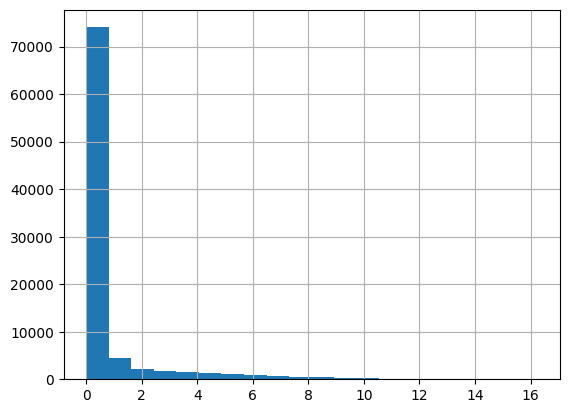

In [19]:
def bin_image(image_matrix, bin_size=4):
    h, w = image_matrix.shape
    
    # Ensure dimensions are divisible by bin_size
    new_h = (h // bin_size) * bin_size
    new_w = (w // bin_size) * bin_size
    image_matrix = image_matrix[:new_h, :new_w]  # Crop excess pixels

    # Reshape and bin
    binned_matrix = image_matrix.reshape(new_h // bin_size, bin_size, new_w // bin_size, bin_size).mean(axis=(1, 3))
    return binned_matrix

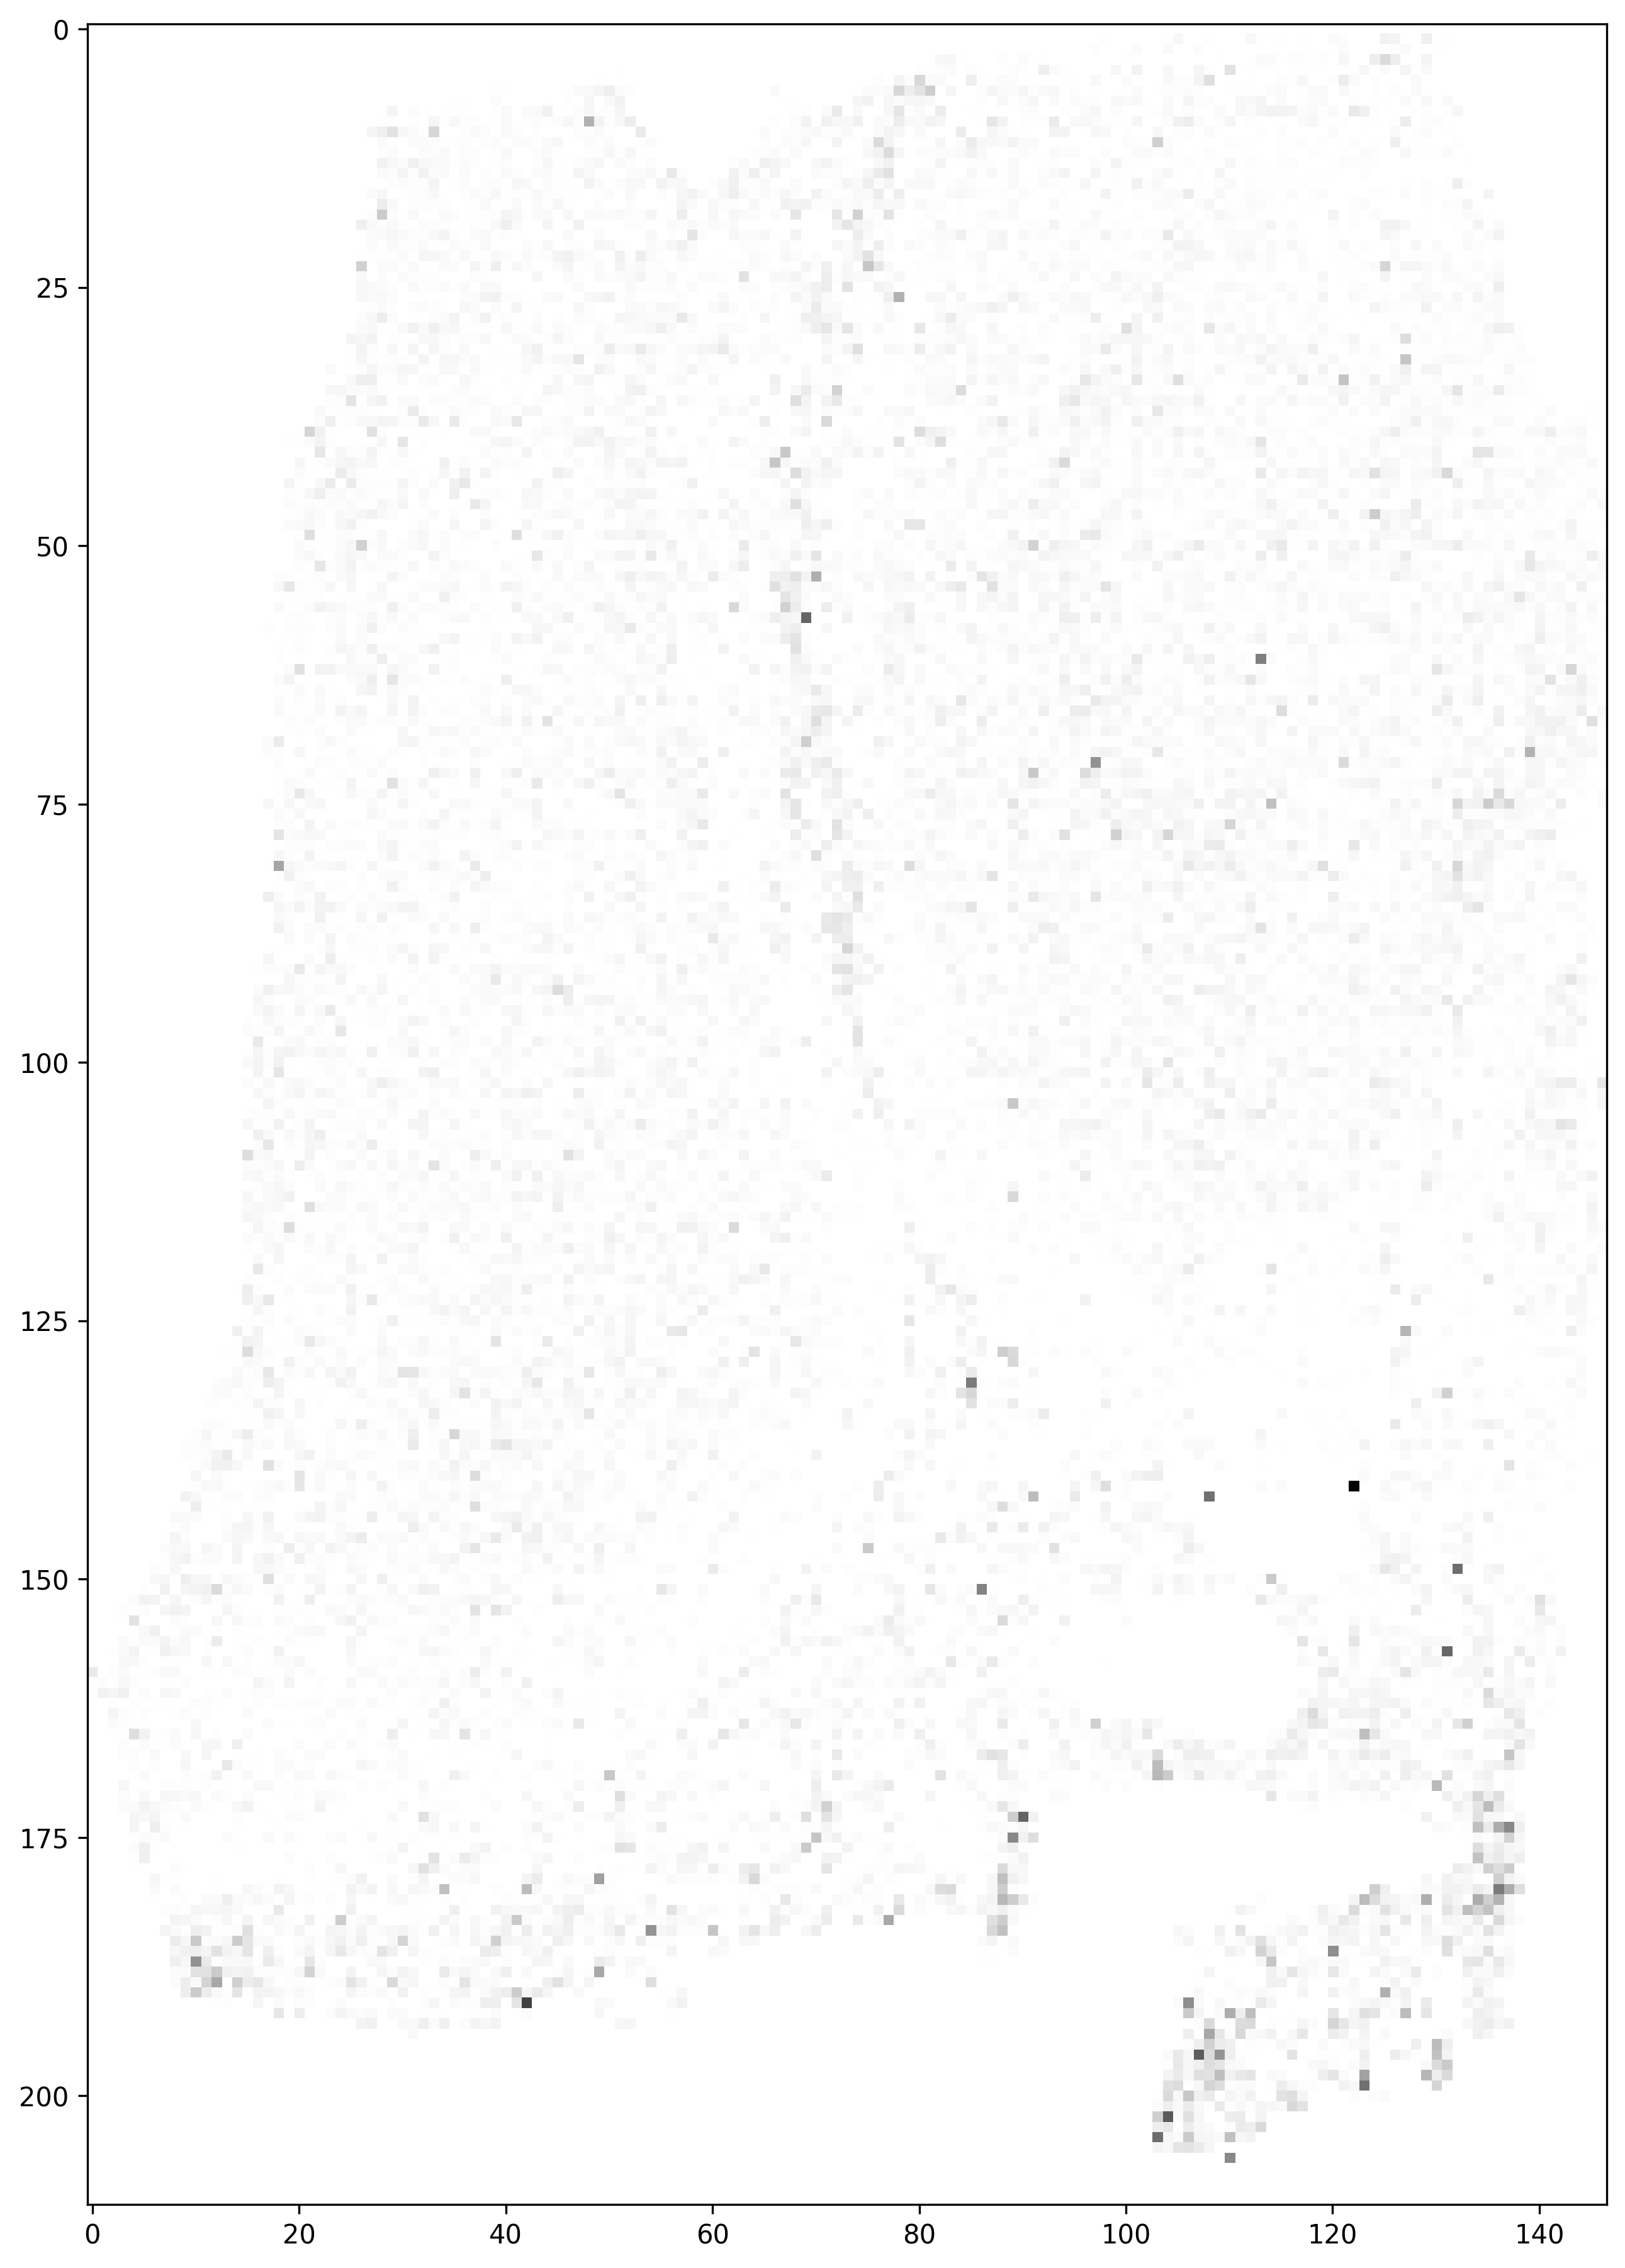

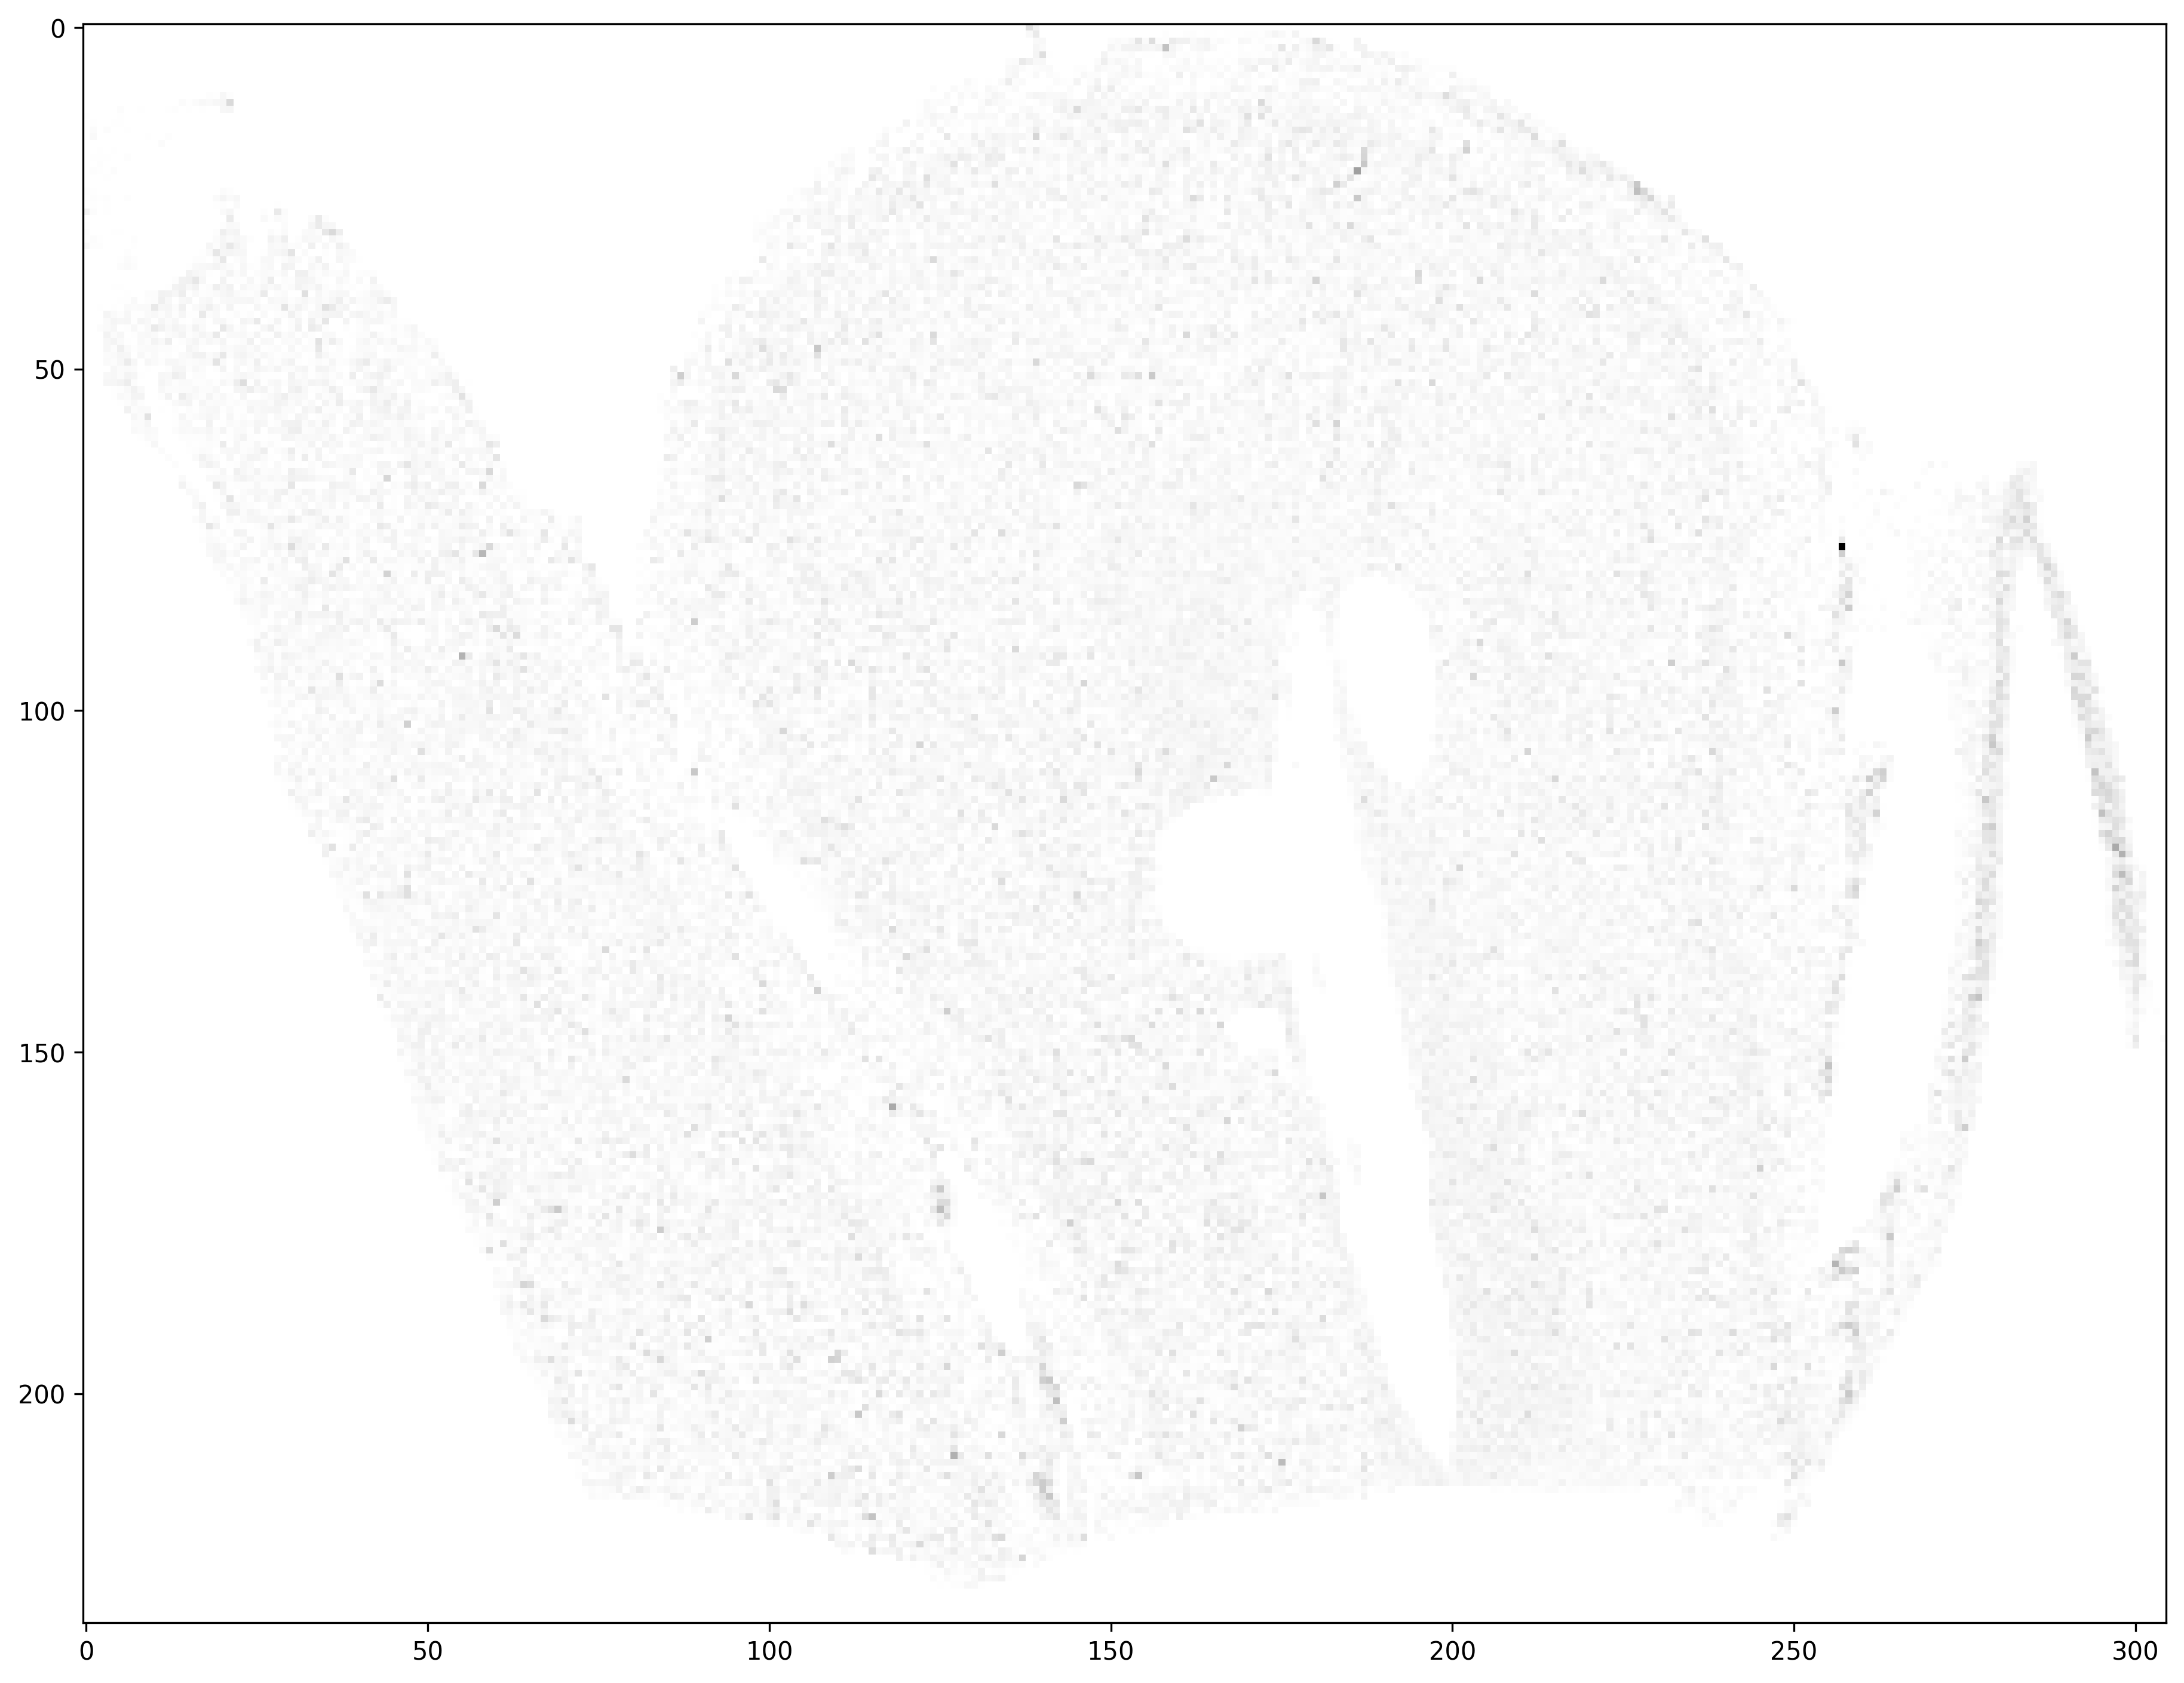

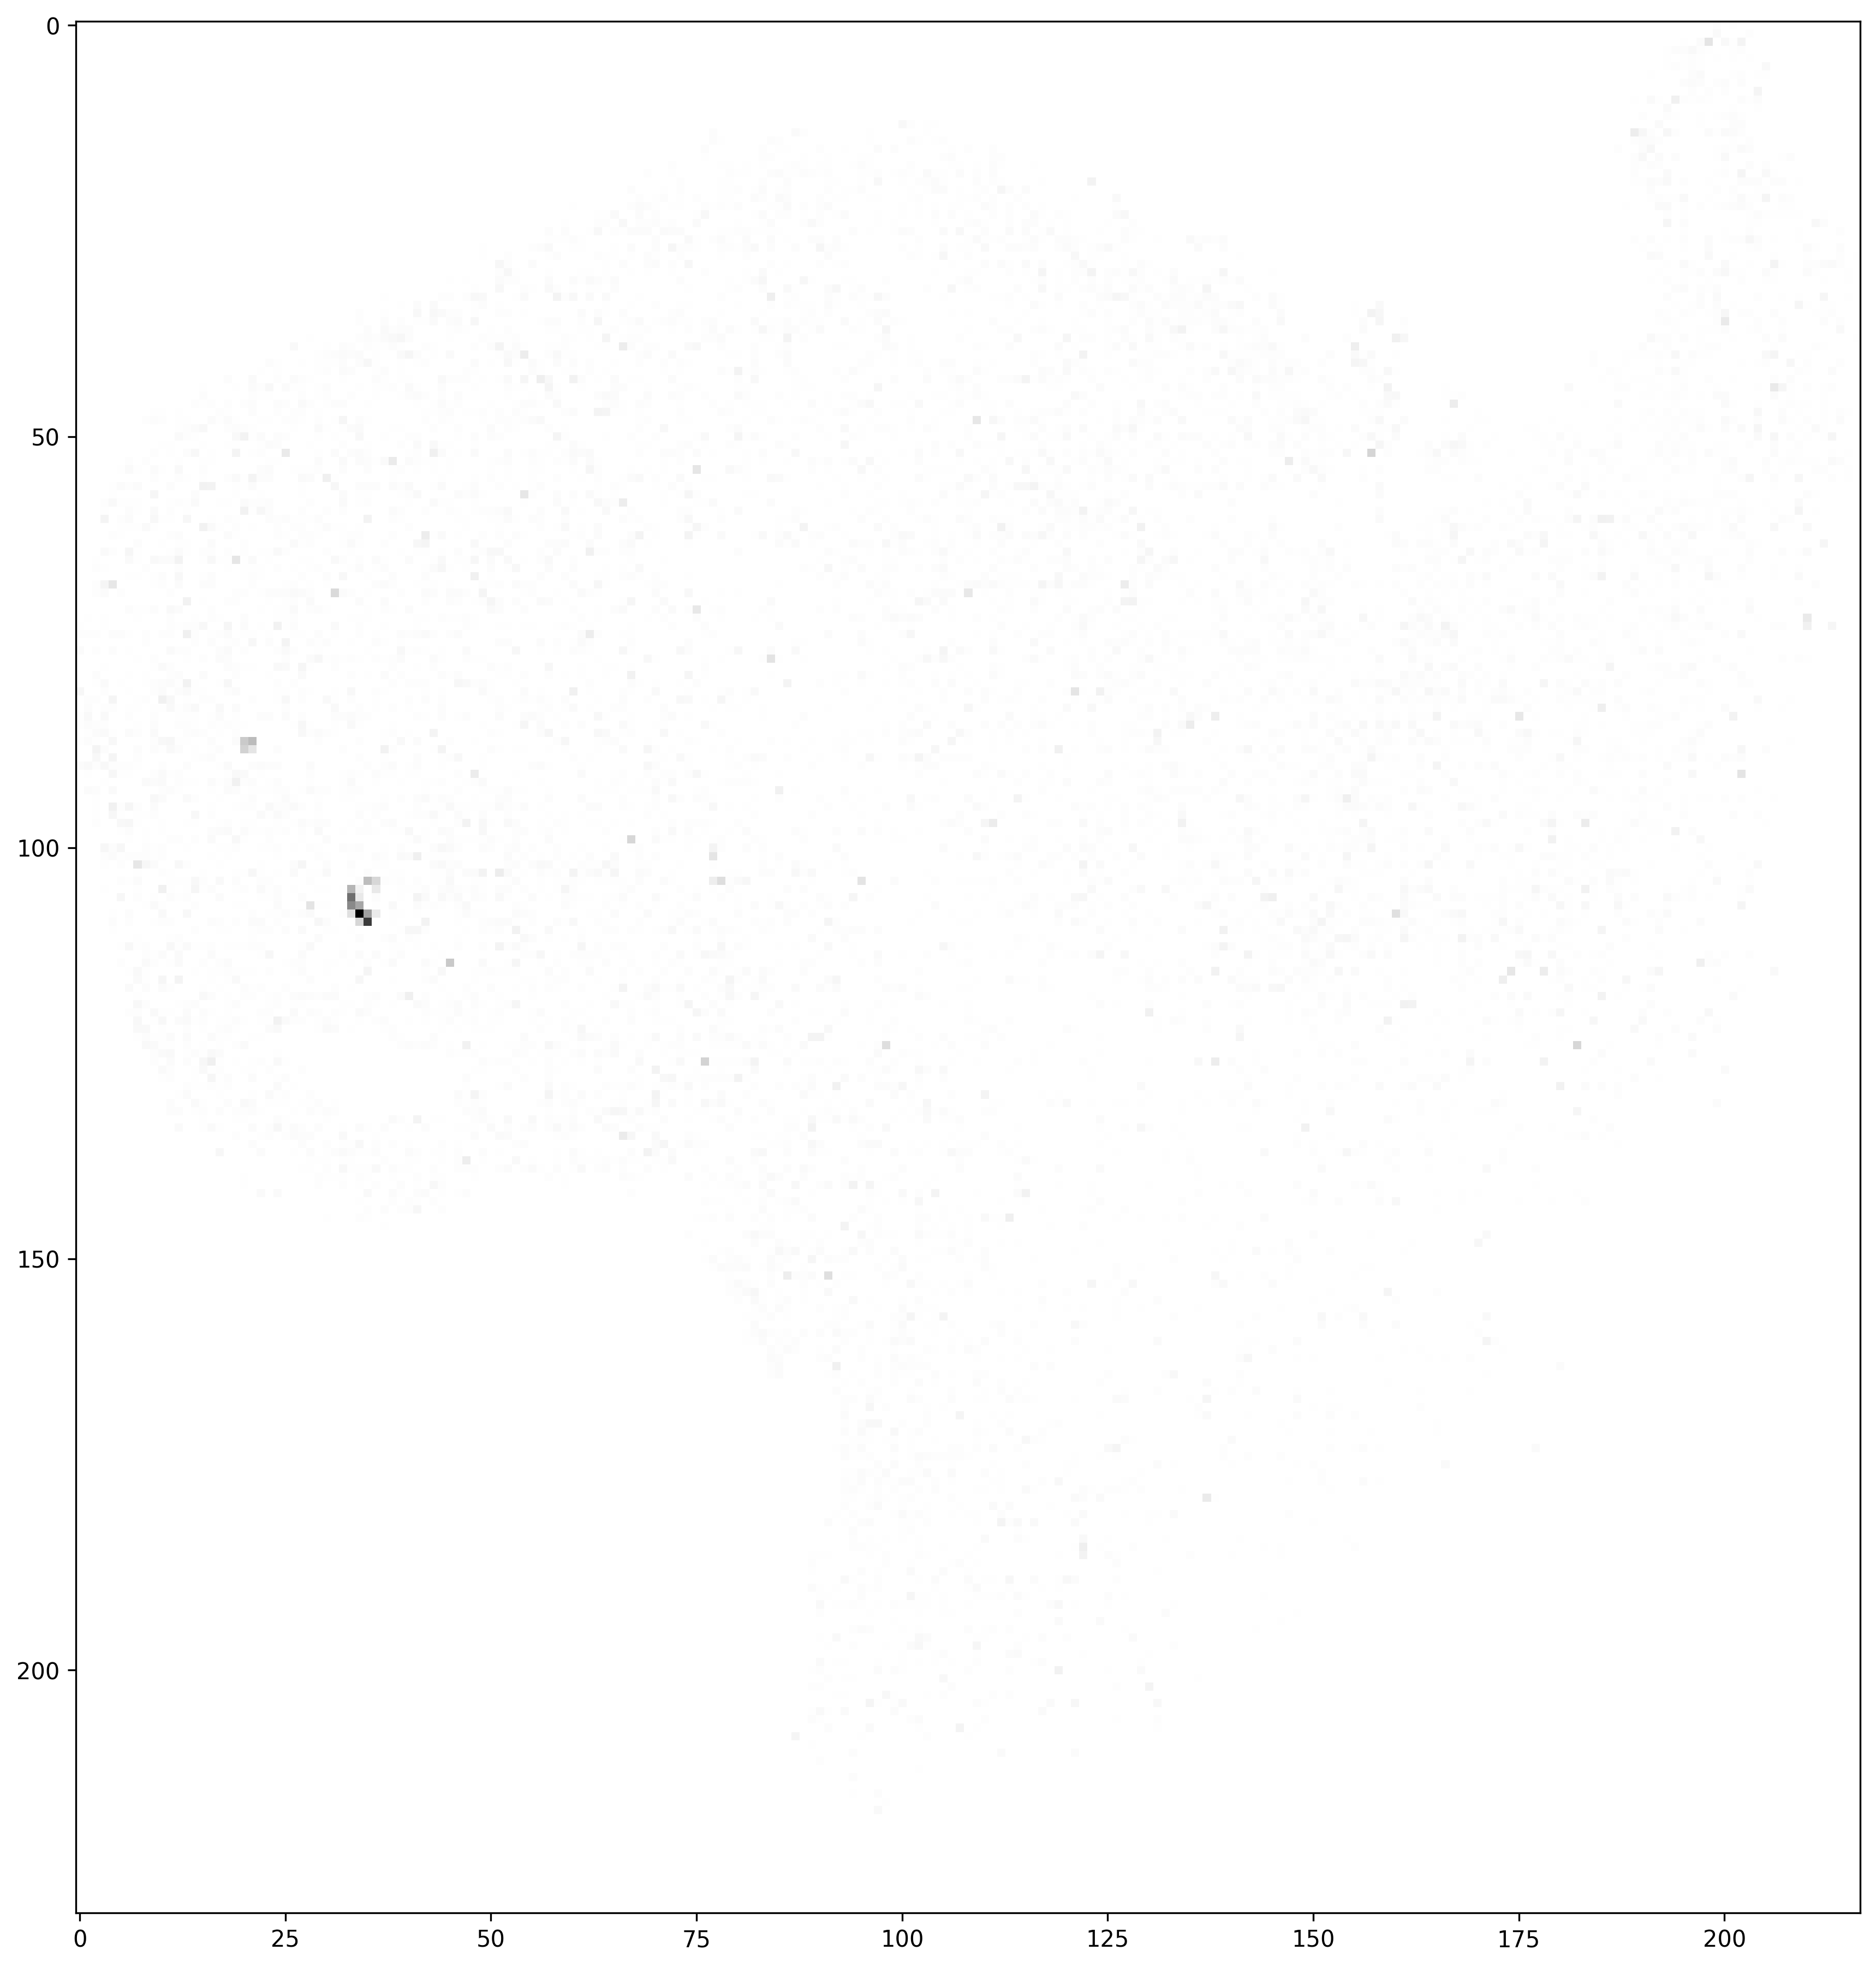

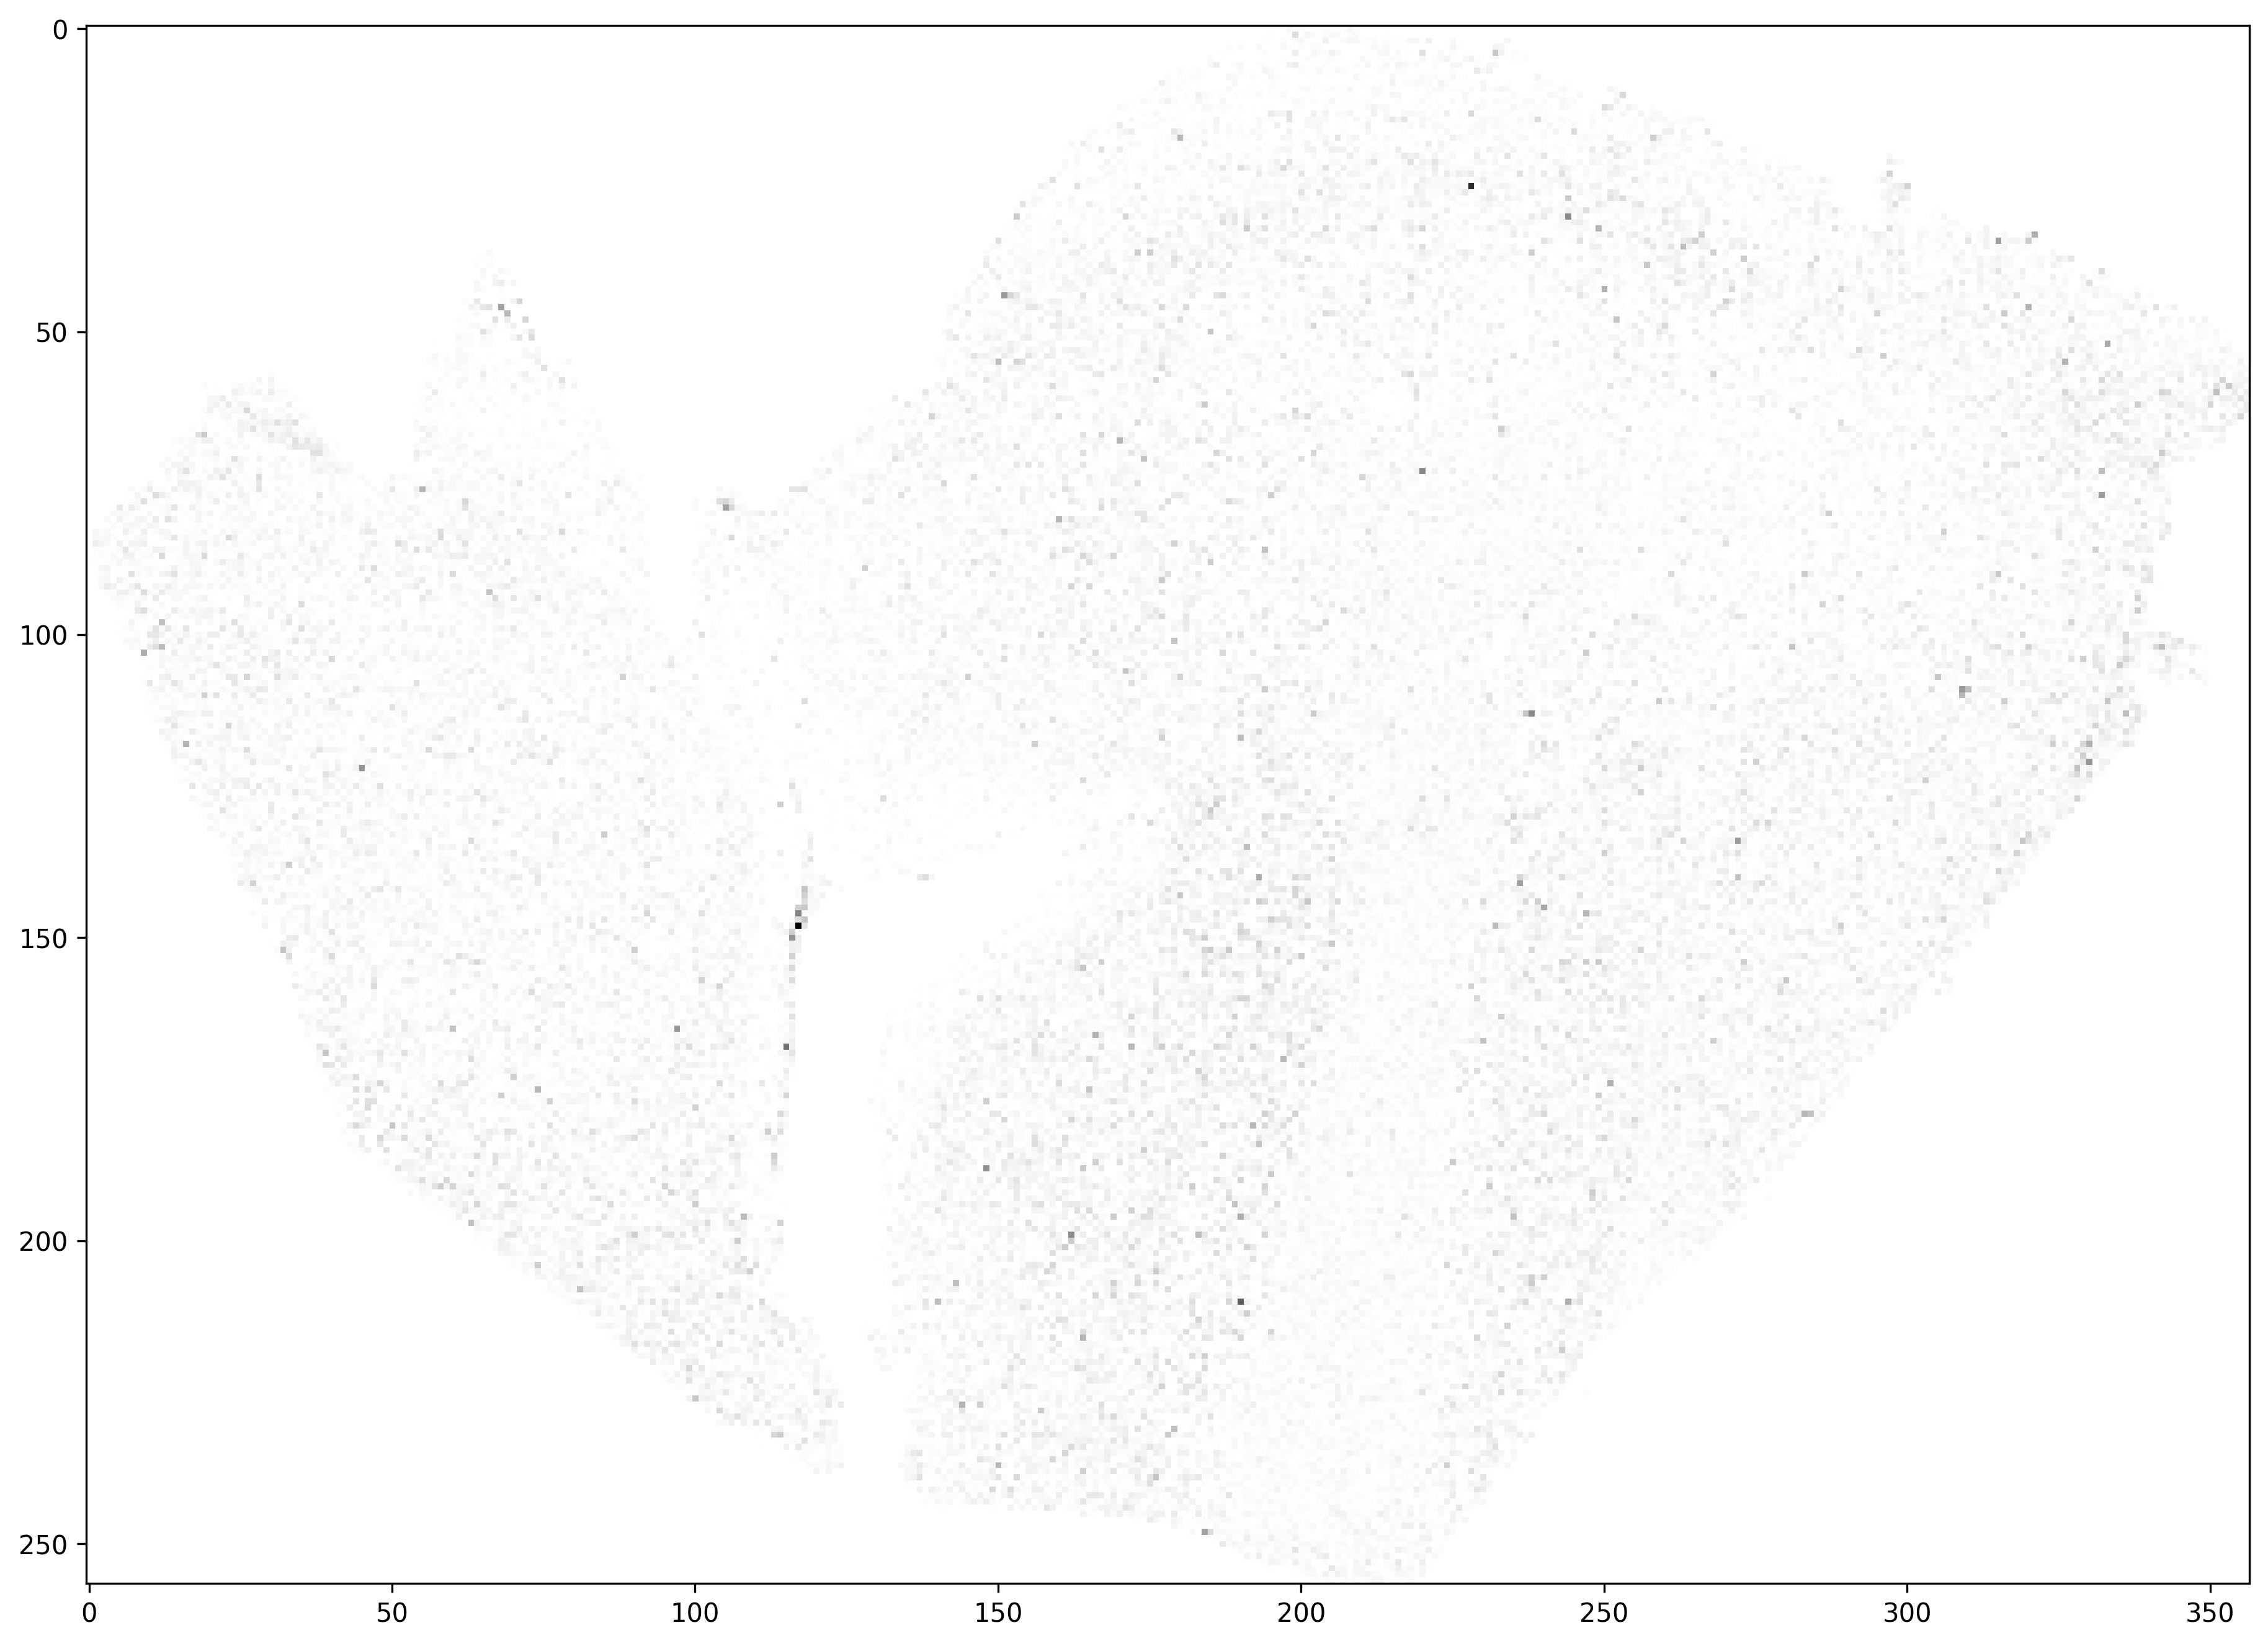

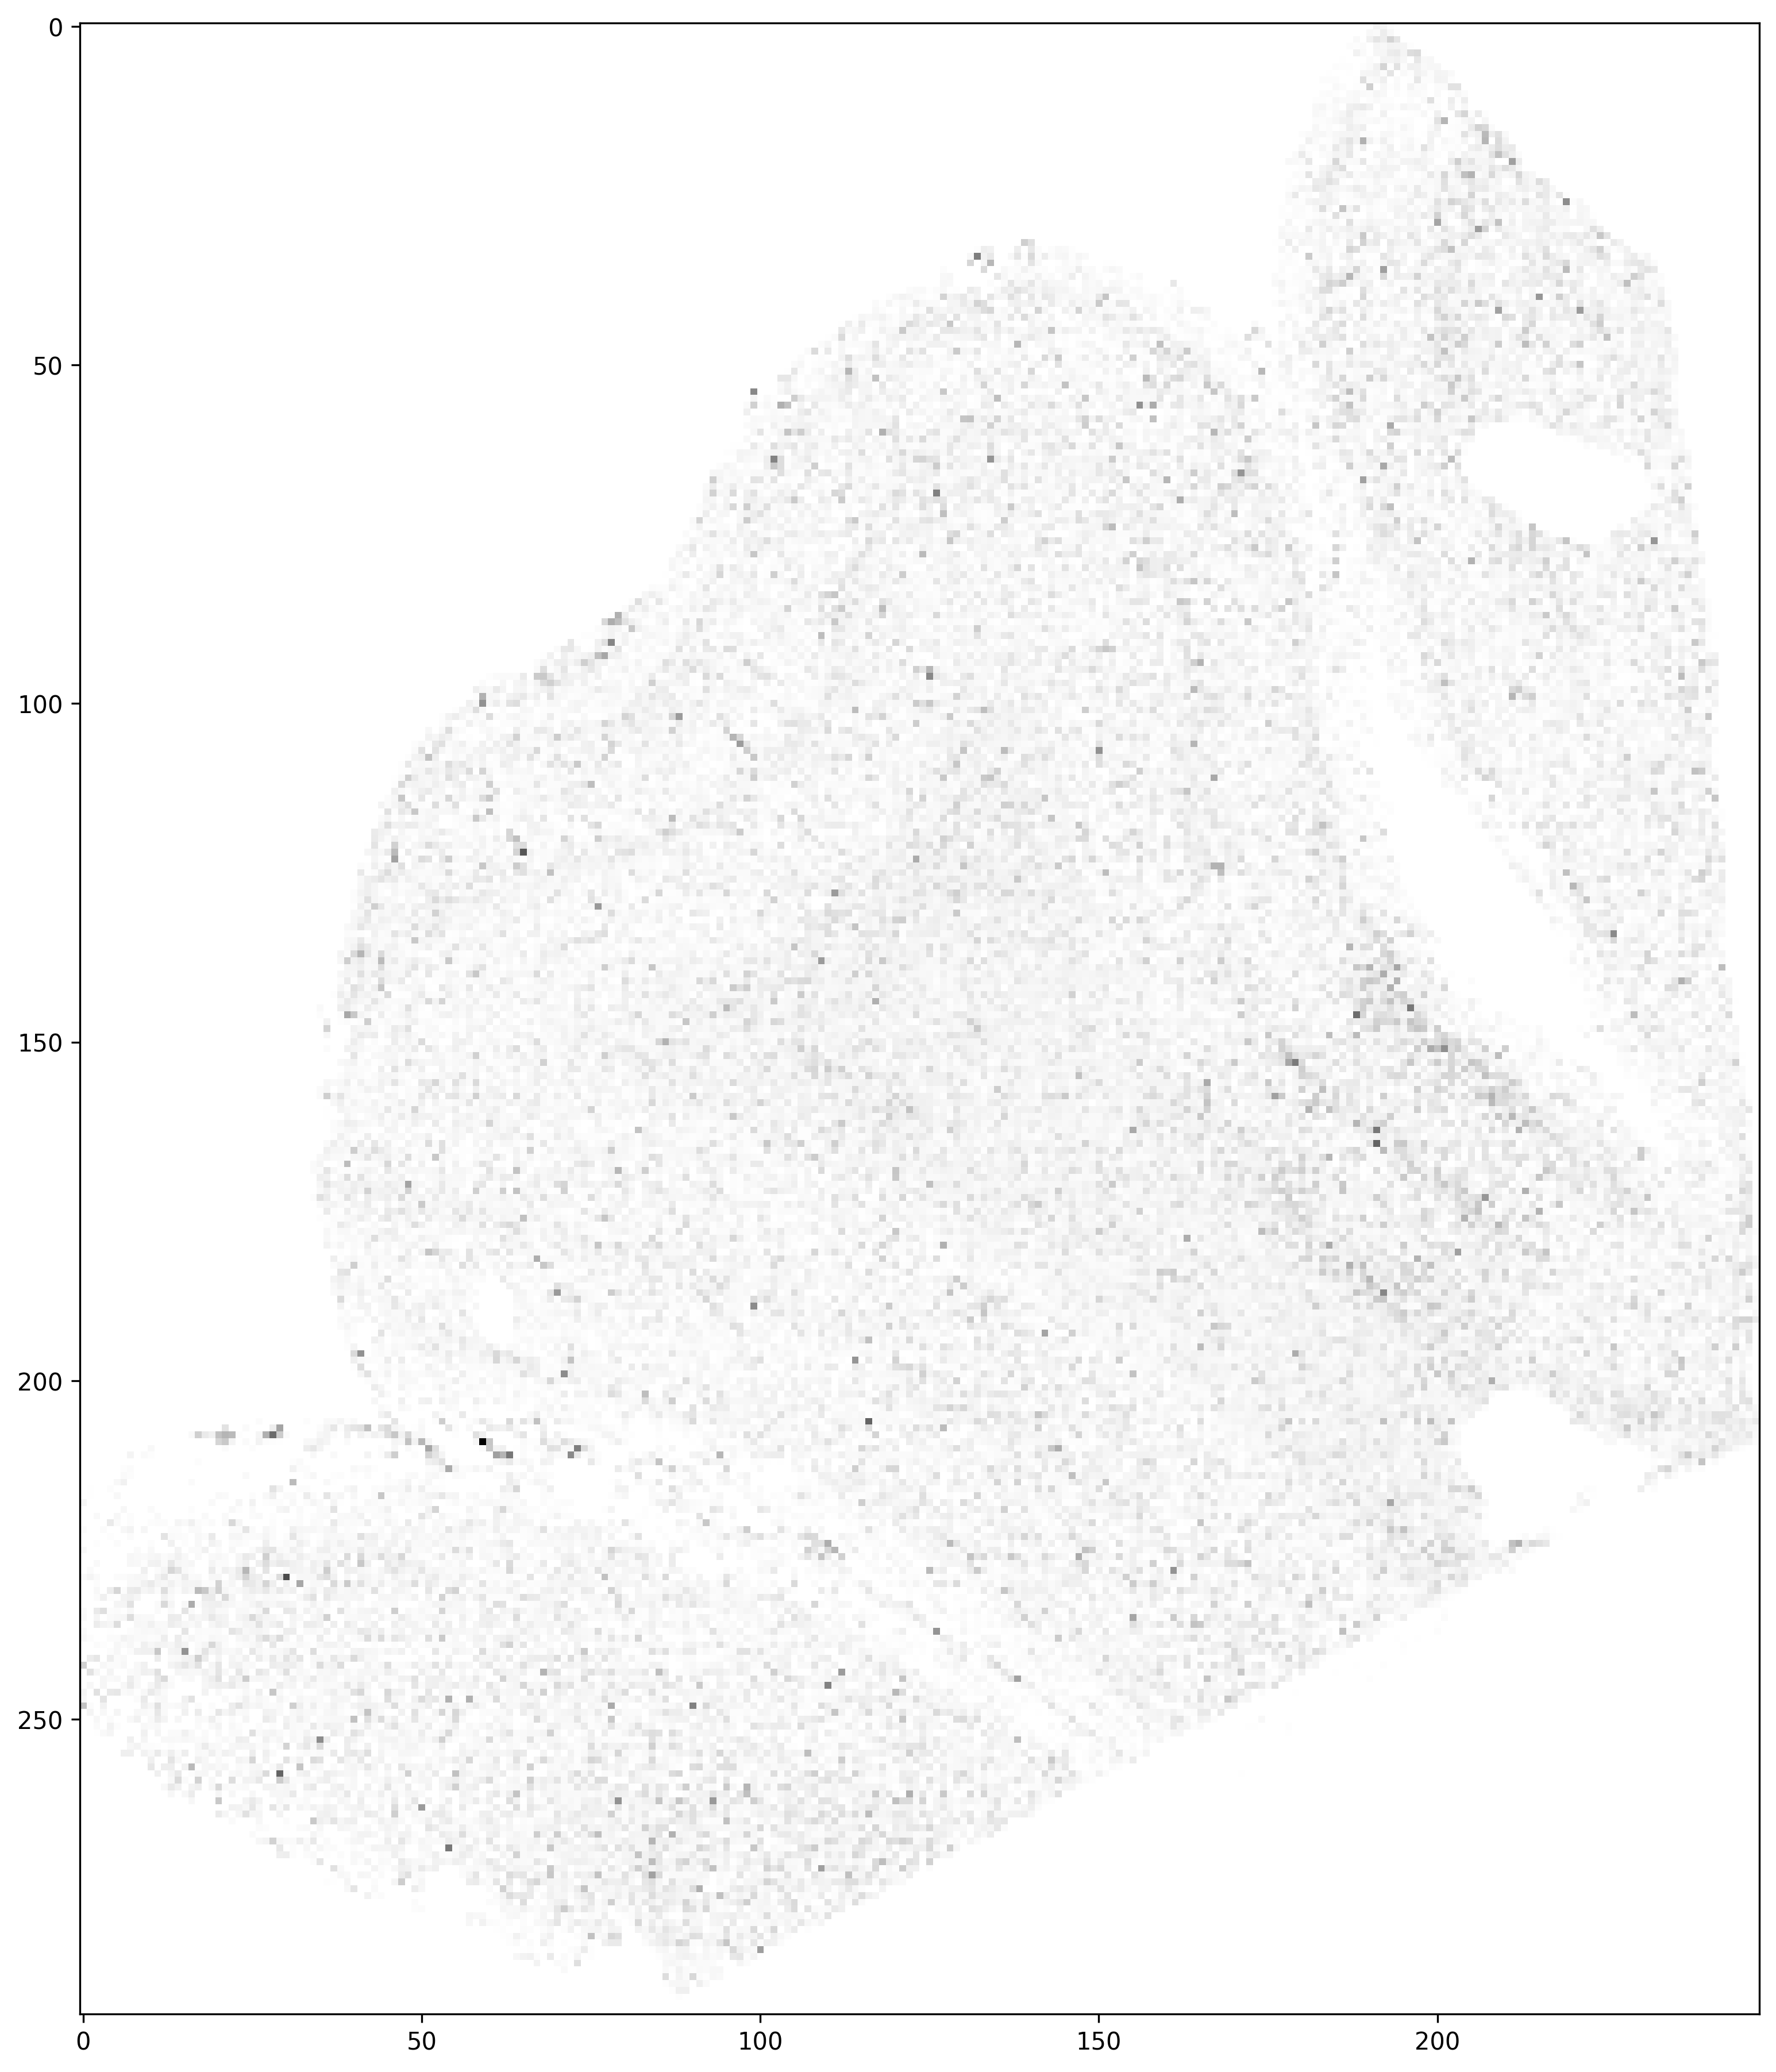

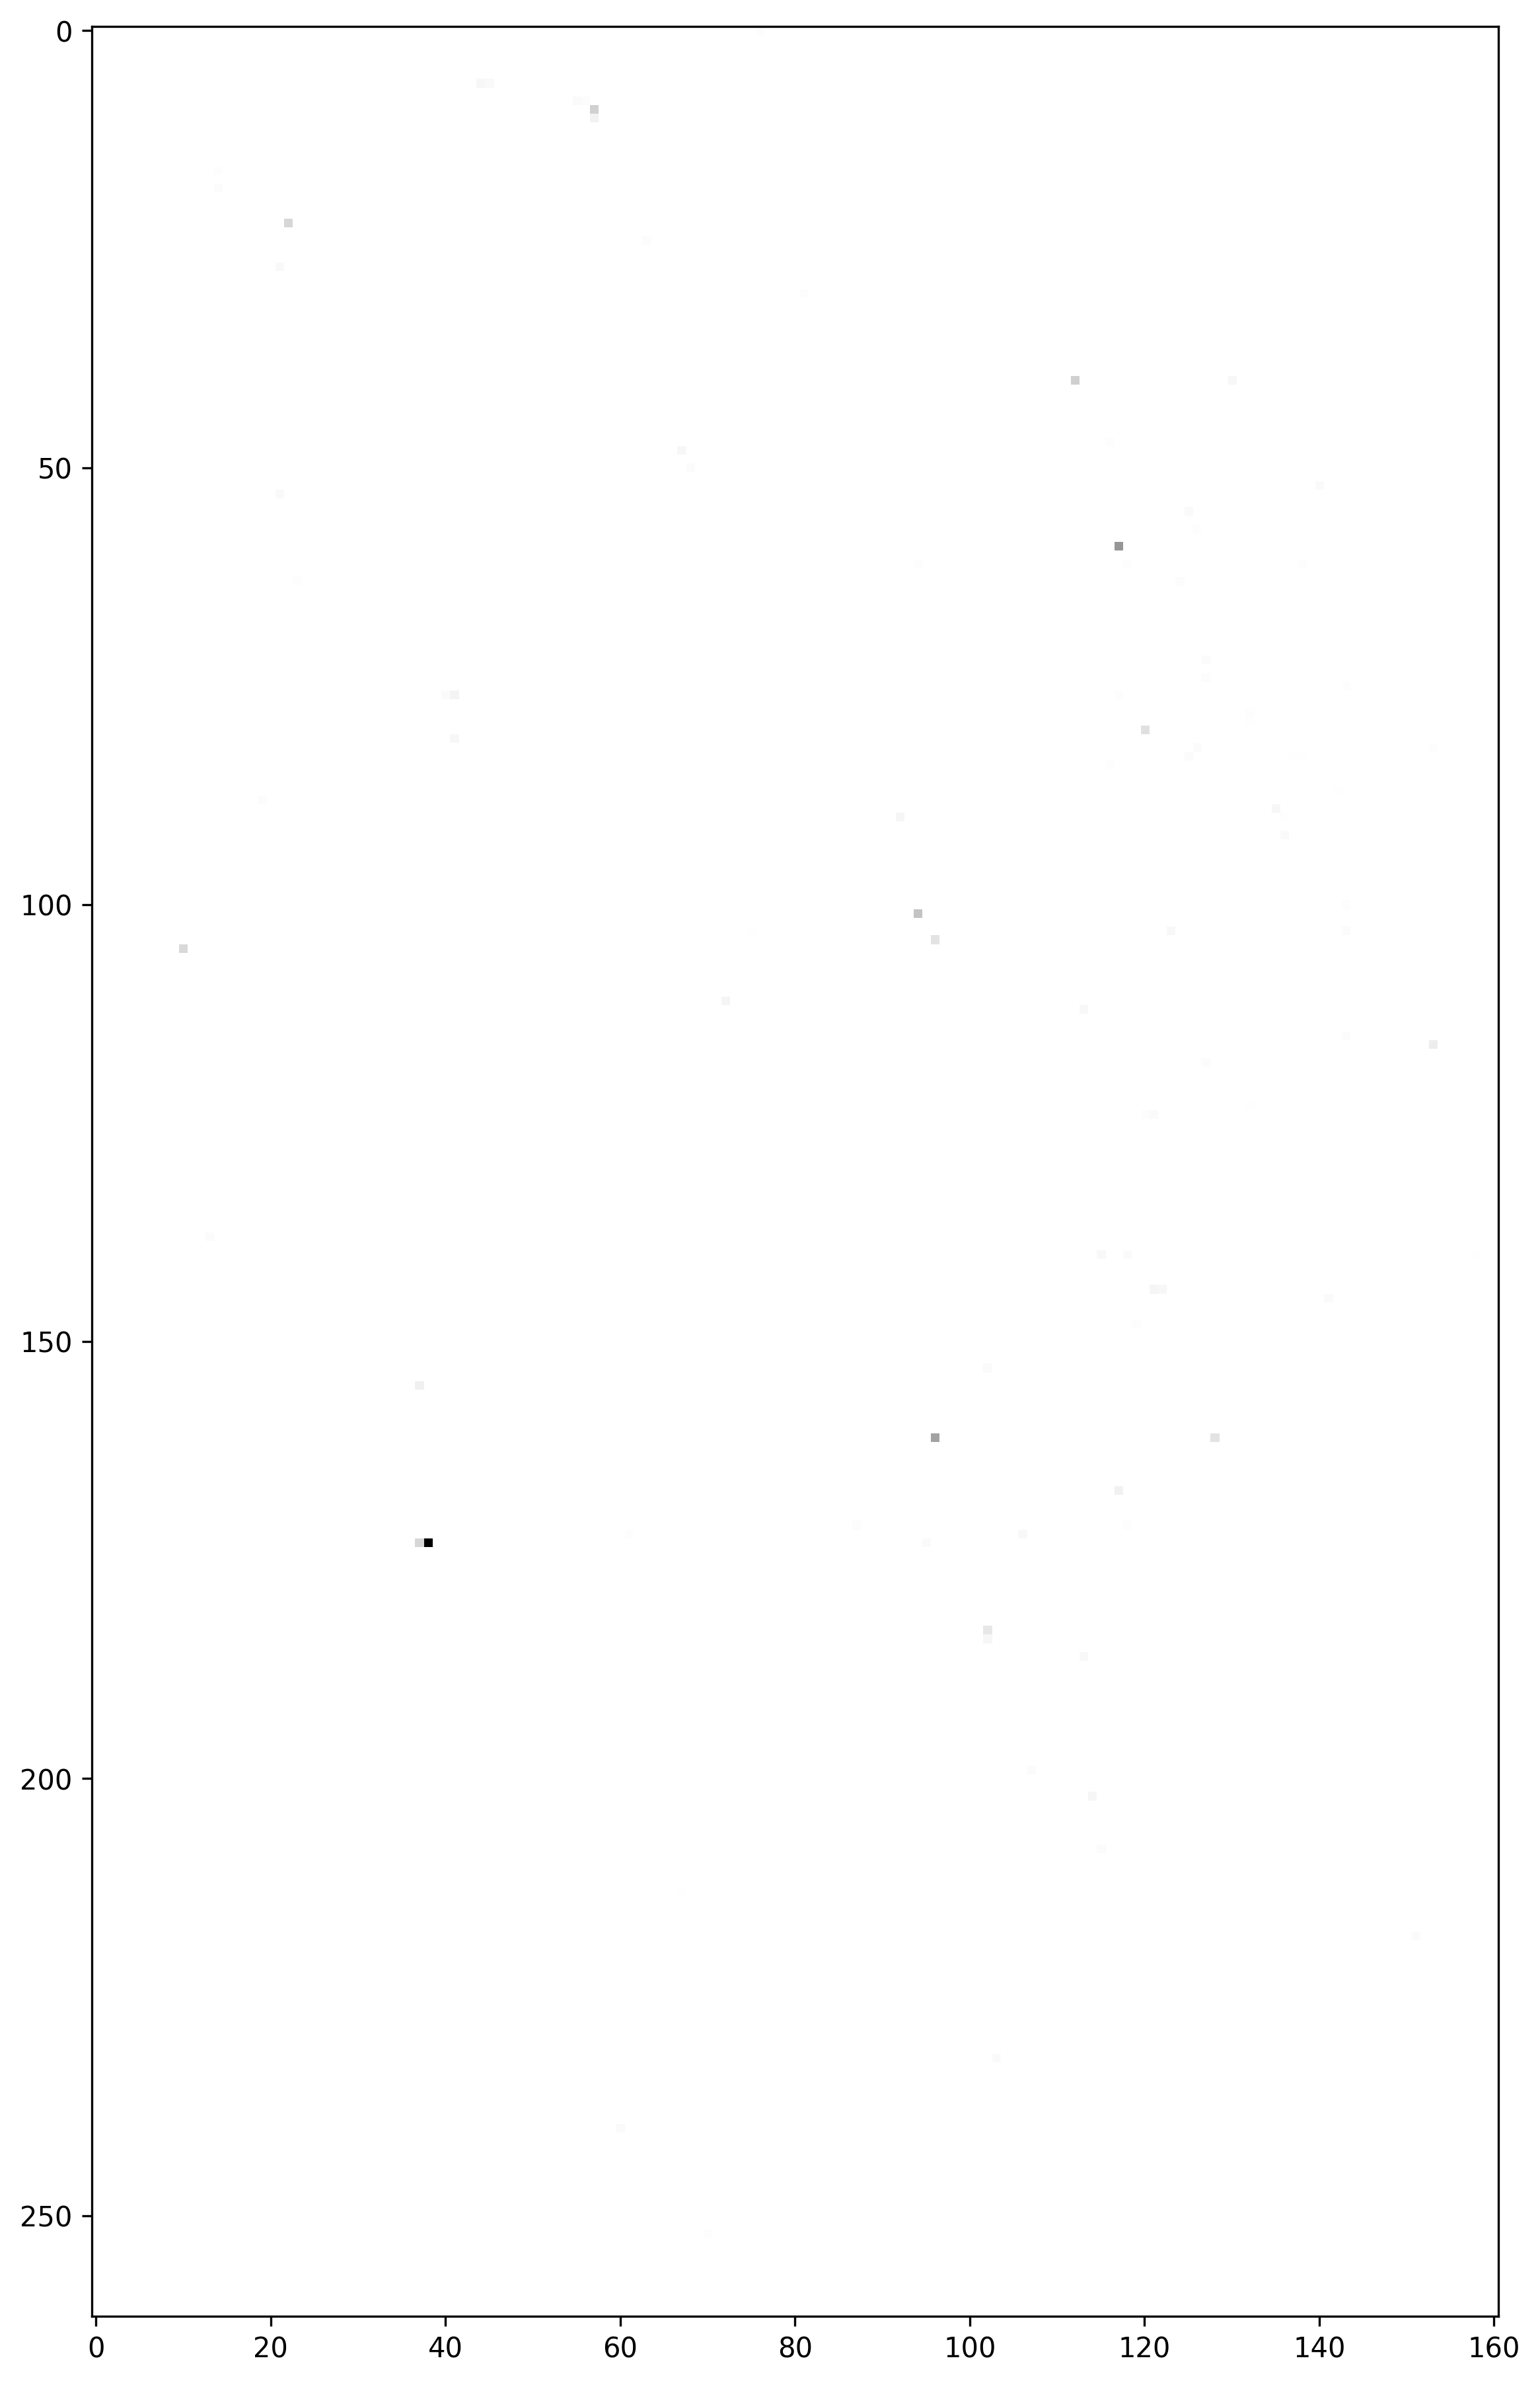

In [32]:
n = 0
for n in range(0,len(paths)):
    bin_size = 128
    df = pd.read_csv(paths[n])
    sample_id = paths[n].split('Br')[1].split('_DLPFC')[0]

    # Determine number of elements in X of matrix
    X = df['XMax'].max()-df['XMin'].min()

    # Determin number of elements in Y of matrix
    Y = df['YMax'].max()-df['YMin'].min()

    def make_matrix(column):
        image = np.zeros(shape=(X,Y))

        for element in range(0, len(df[column])):
            for x in range(df['XMin'][element]-df['XMin'].min(), df['XMax'][element]-df['XMax'].min()):
                for y in range(df['YMin'][element]-df['YMin'].min(), df['YMax'][element]-df['YMax'].min()):
                    image[x, y] = df[column][element]*255
        return image

    image = make_matrix('DAPI (DAPI) Positive')

    pd.DataFrame(bin_image(image, bin_size = bin_size)).to_csv('../../processed_data/08_validation_oligos/Br%s_array_DAPI_%sx%sbinned_for_masking.txt' % (sample_id, bin_size, bin_size))

    from matplotlib import pyplot as plt

    plt.figure(figsize=(15, 15), dpi=300)
    plt.imshow(bin_image(image, bin_size = bin_size), interpolation = 'nearest', cmap = 'Greys')
    plt.gca().set_axis_off()
    plt.savefig('../../plots/08_validation_oligos/Br%s_array_DAPI_%sx%sbinned_for_masking.png' % (sample_id, bin_size, bin_size), bbox_inches = 'tight', dpi = 300)
    plt.show()

In [38]:
df.columns

Index(['Image Location', 'Analysis Region', 'Algorithm Name', 'Object Id',
       'XMin', 'XMax', 'YMin', 'YMax', 'MBP_Oligo', 'HPCAL1_L2_neuron',
       'DAPI (DAPI) Positive', 'DAPI (DAPI) Positive Nucleus',
       'DAPI (DAPI) Nucleus Intensity', 'DAPI (DAPI) Positive Cytoplasm',
       'DAPI (DAPI) Cytoplasm Intensity', 'DAPI (DAPI) Positive Membrane',
       'DAPI (DAPI) Membrane Intensity', 'MBP (Opal 520) Positive',
       'MBP (Opal 520) Positive Nucleus', 'MBP (Opal 520) Nucleus Intensity',
       'MBP (Opal 520) Positive Cytoplasm',
       'MBP (Opal 520) Cytoplasm Intensity',
       'MBP (Opal 520) Positive Membrane', 'MBP (Opal 520) Membrane Intensity',
       'HPCAL1 (Opal 570) Positive', 'HPCAL1 (Opal 570) Positive Nucleus',
       'HPCAL1 (Opal 570) Nucleus Intensity',
       'HPCAL1 (Opal 570) Positive Cytoplasm',
       'HPCAL1 (Opal 570) Cytoplasm Intensity',
       'HPCAL1 (Opal 570) Positive Membrane',
       'HPCAL1 (Opal 570) Membrane Intensity', 'Cell Area (µm²)'

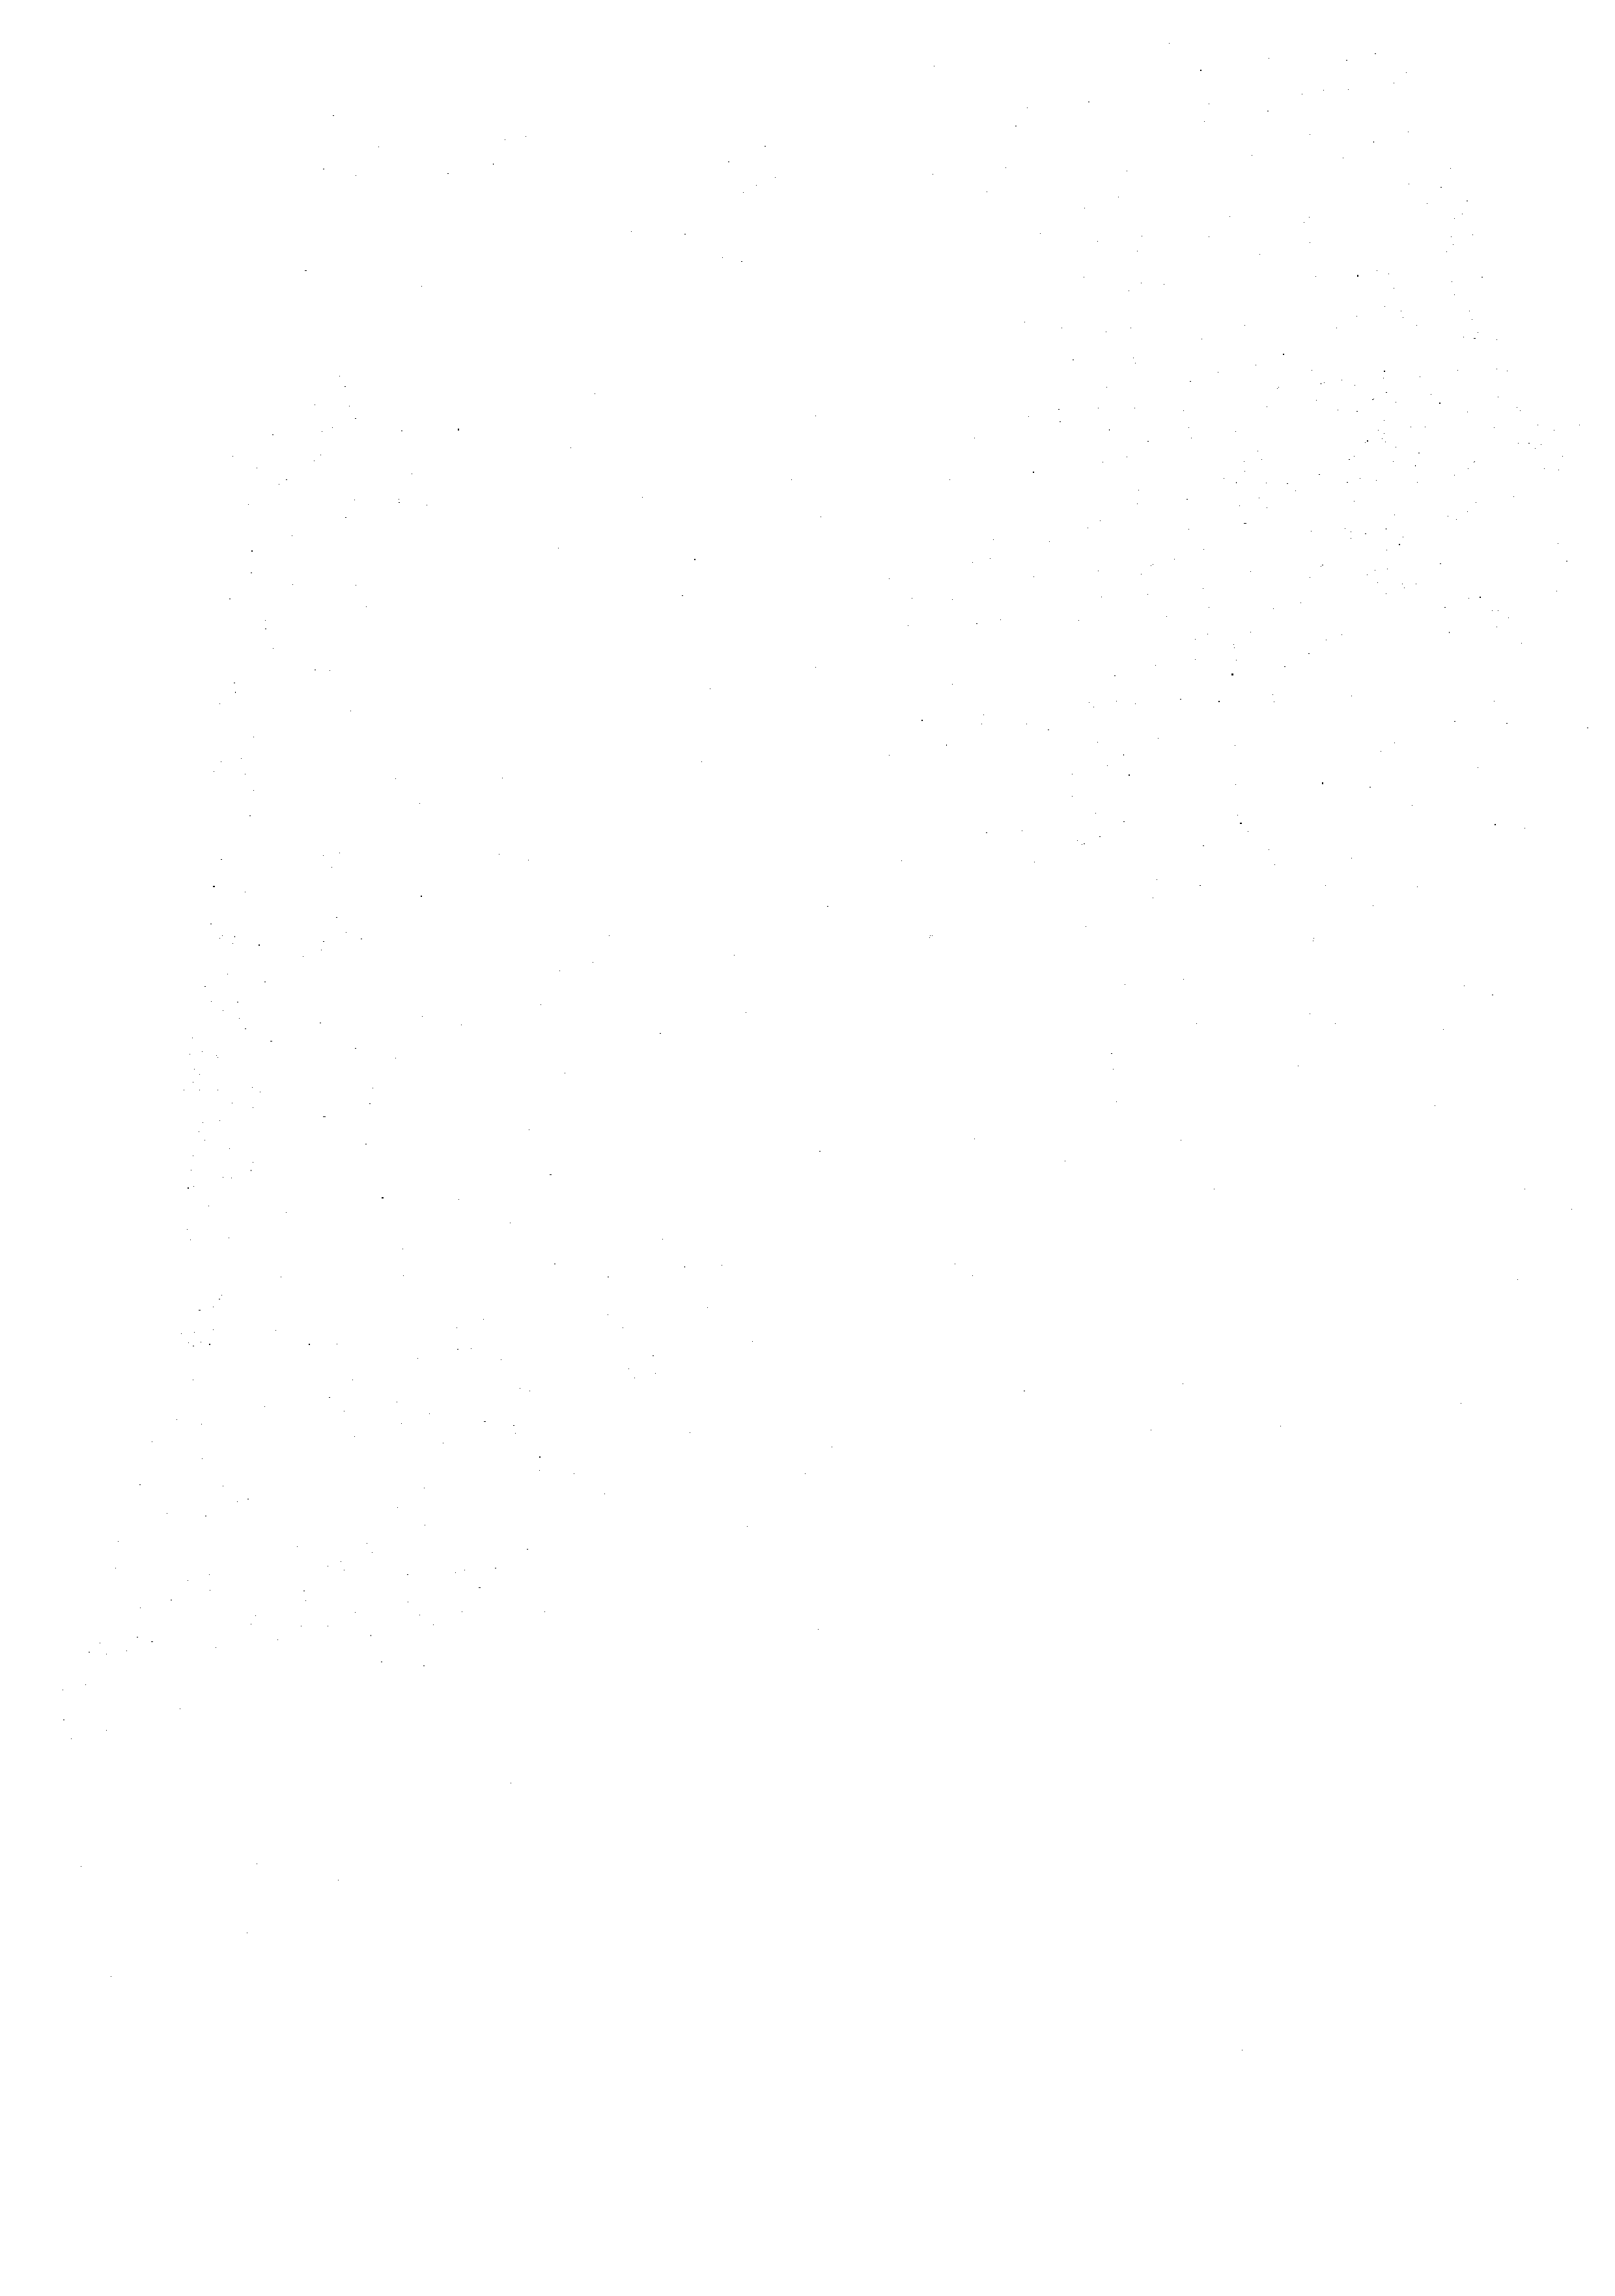

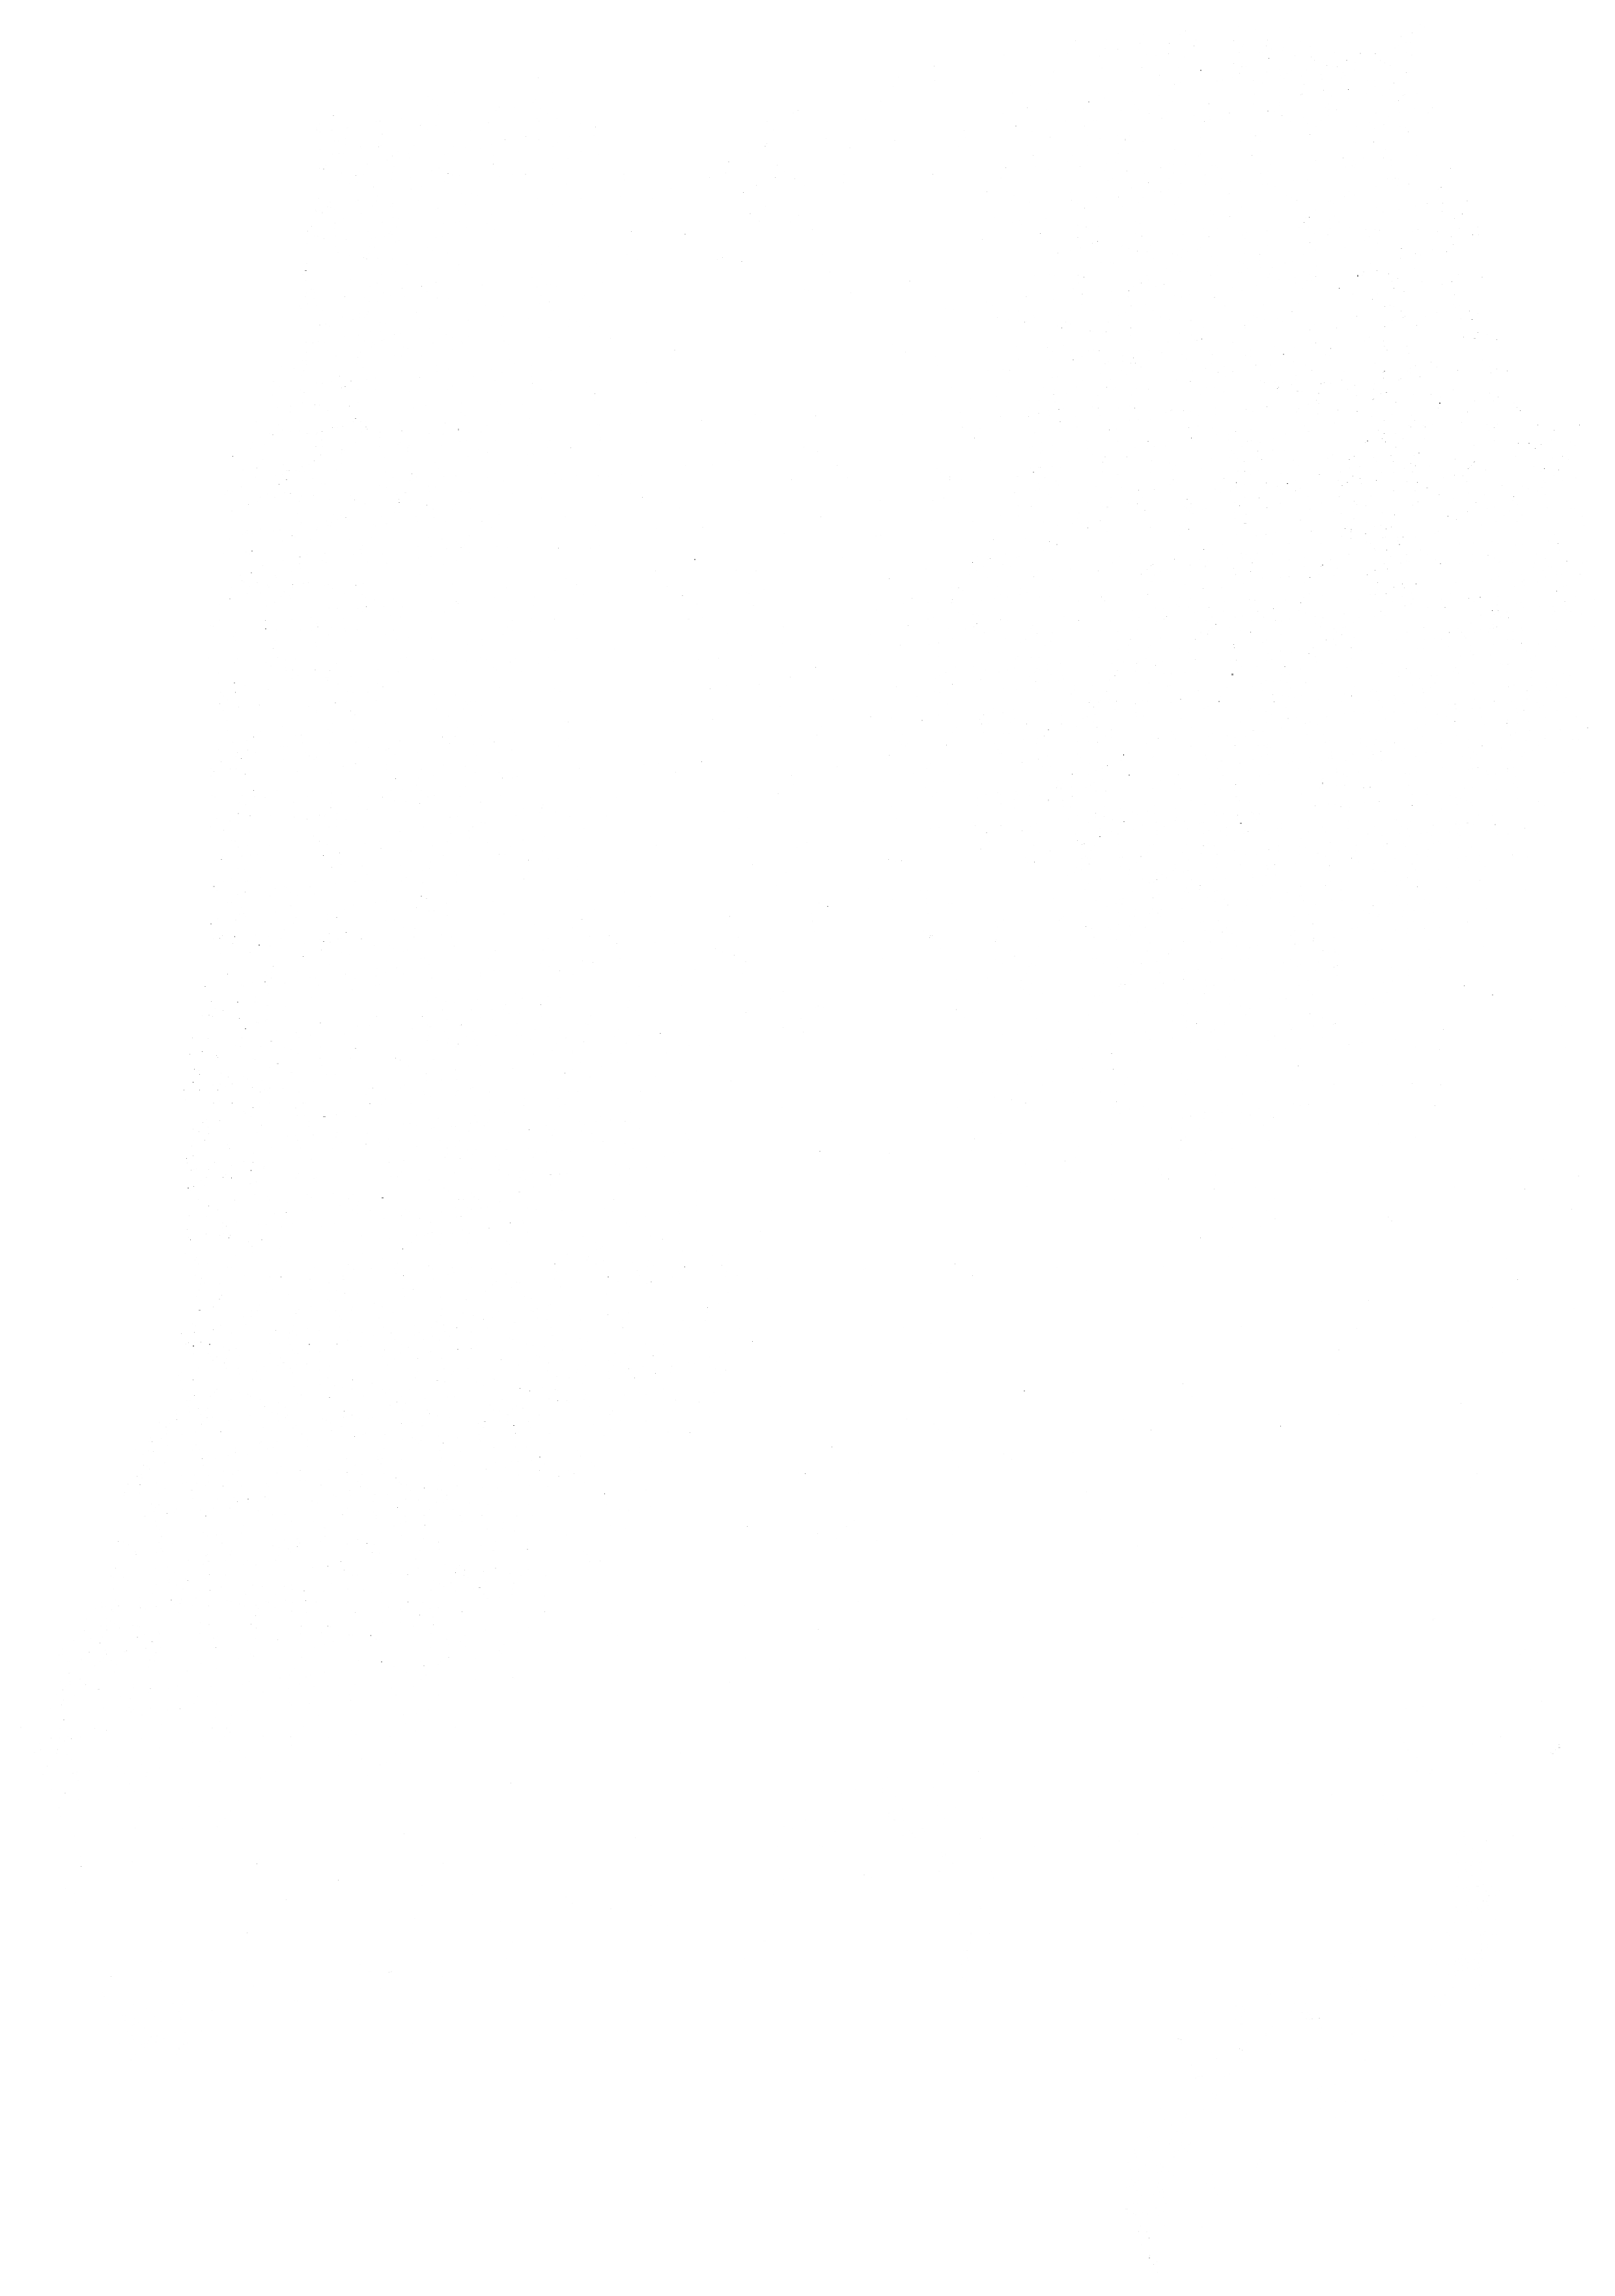

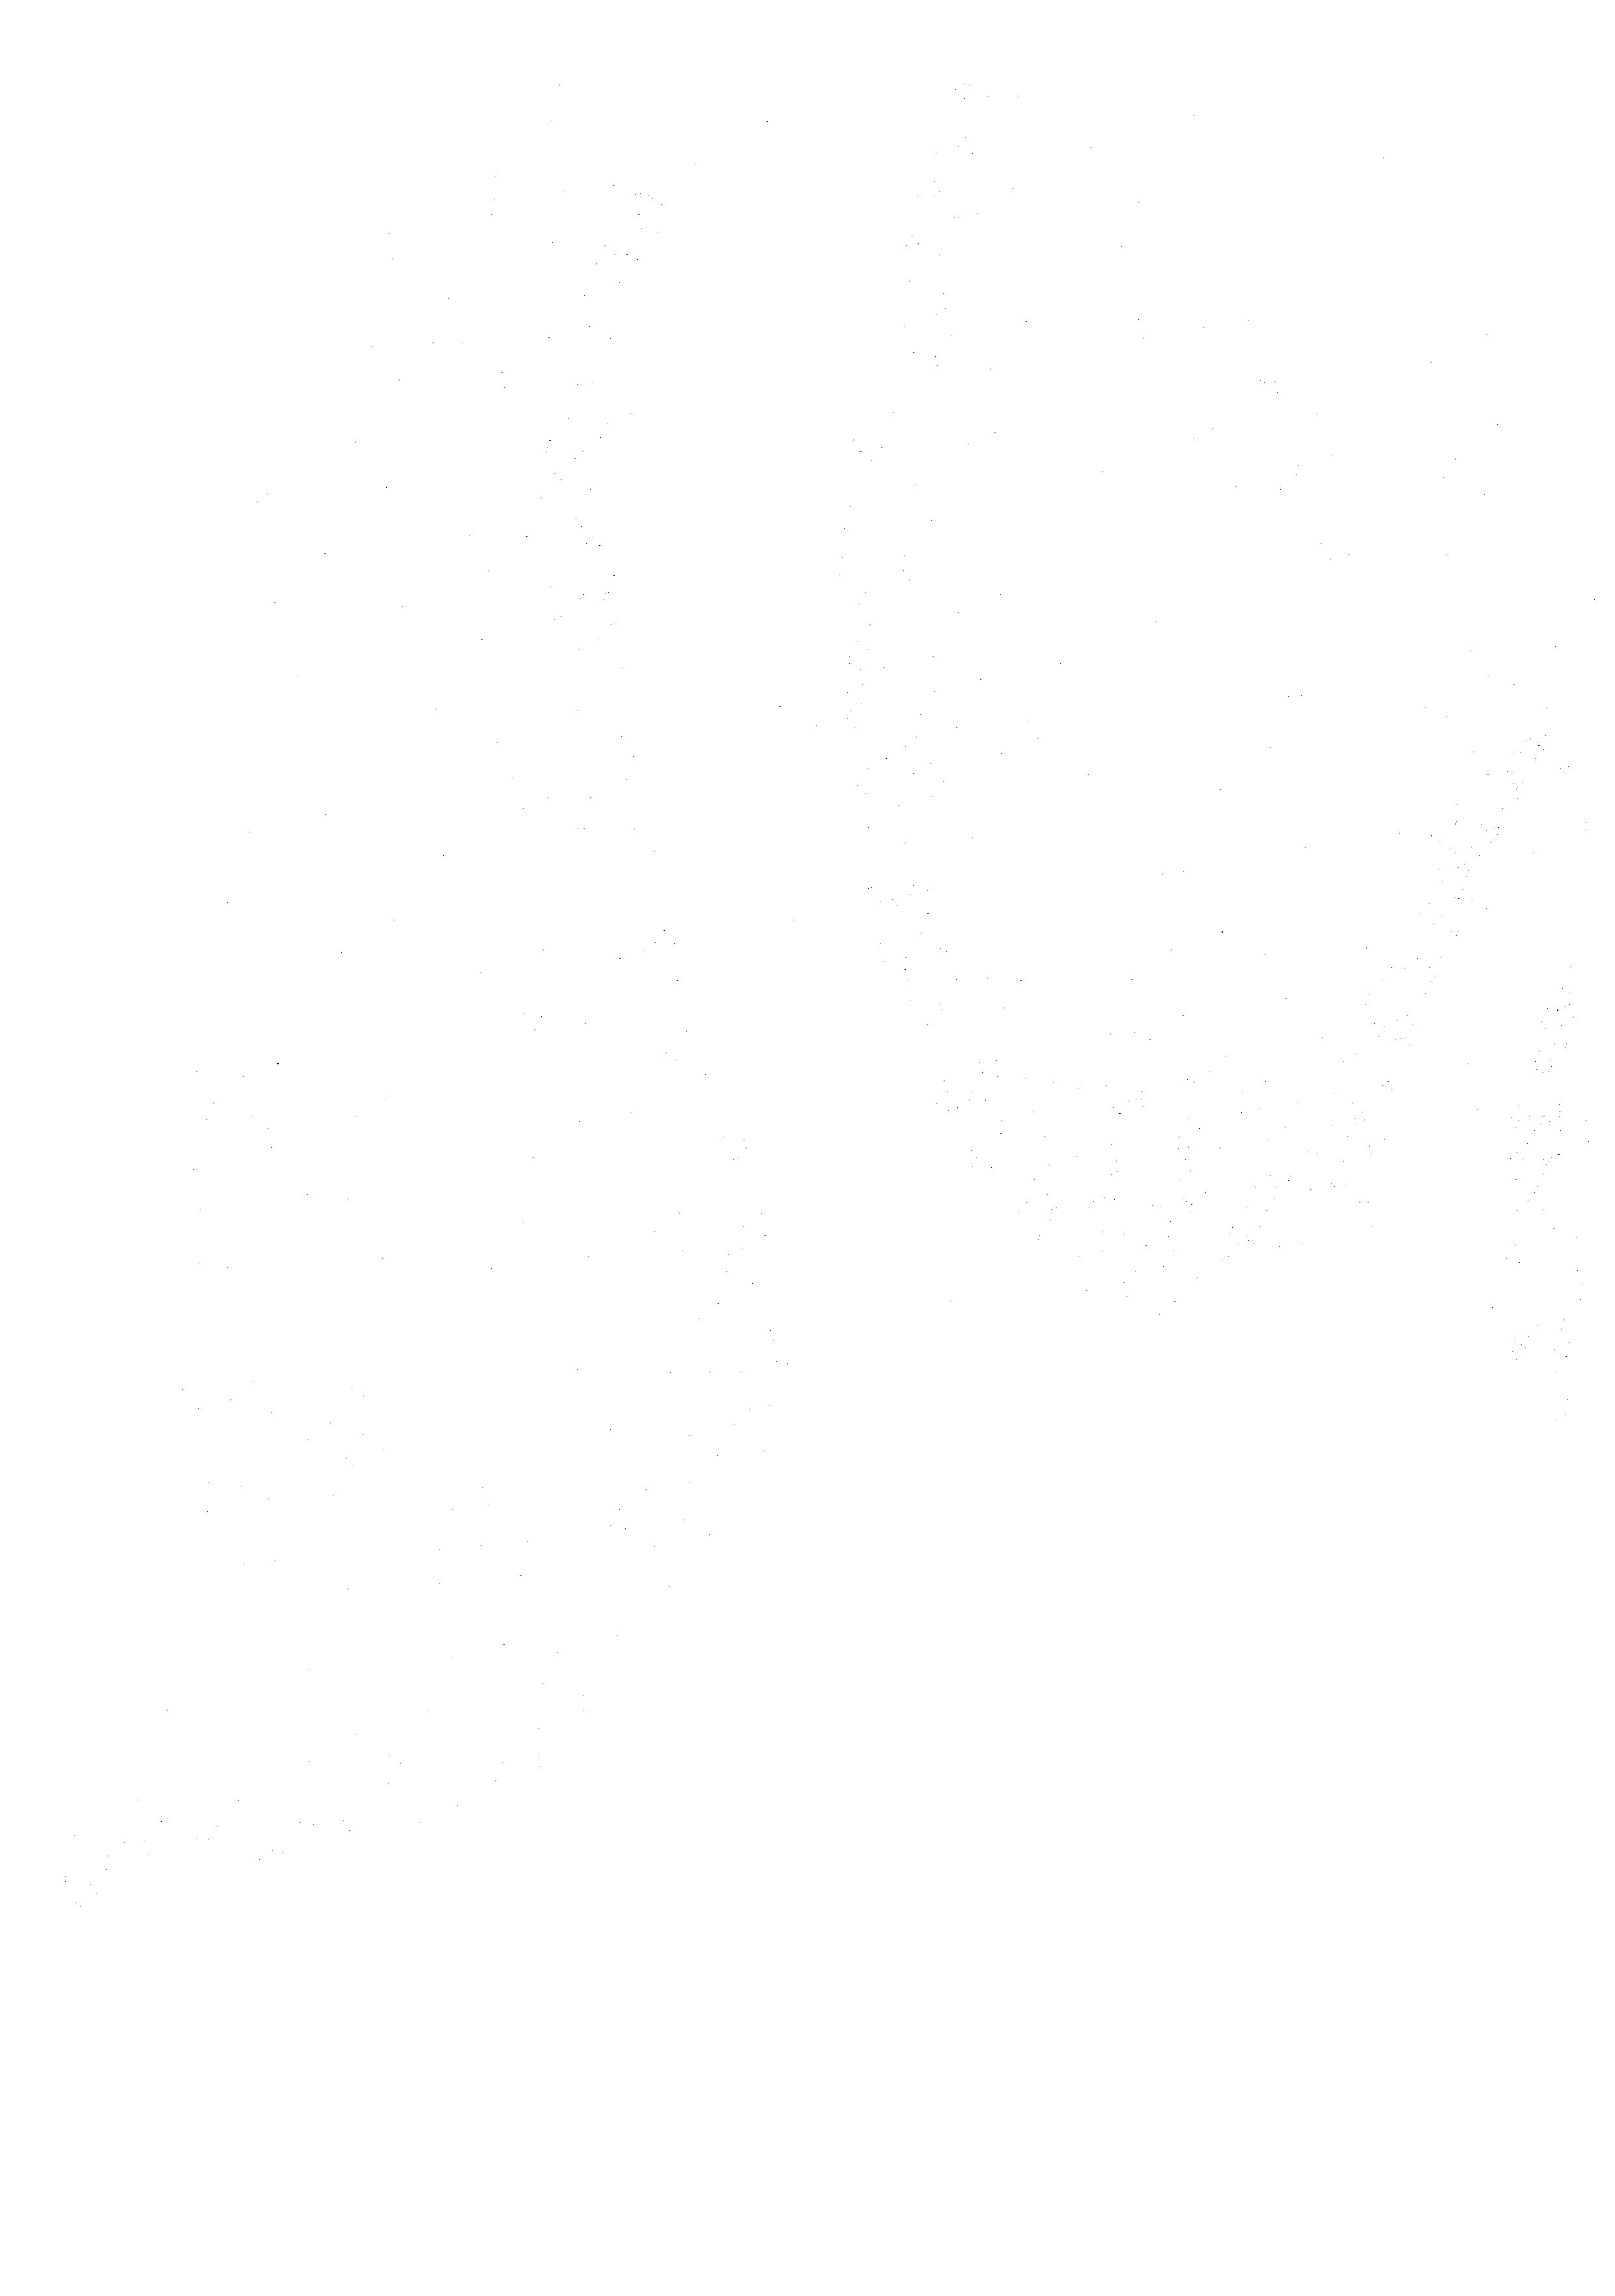

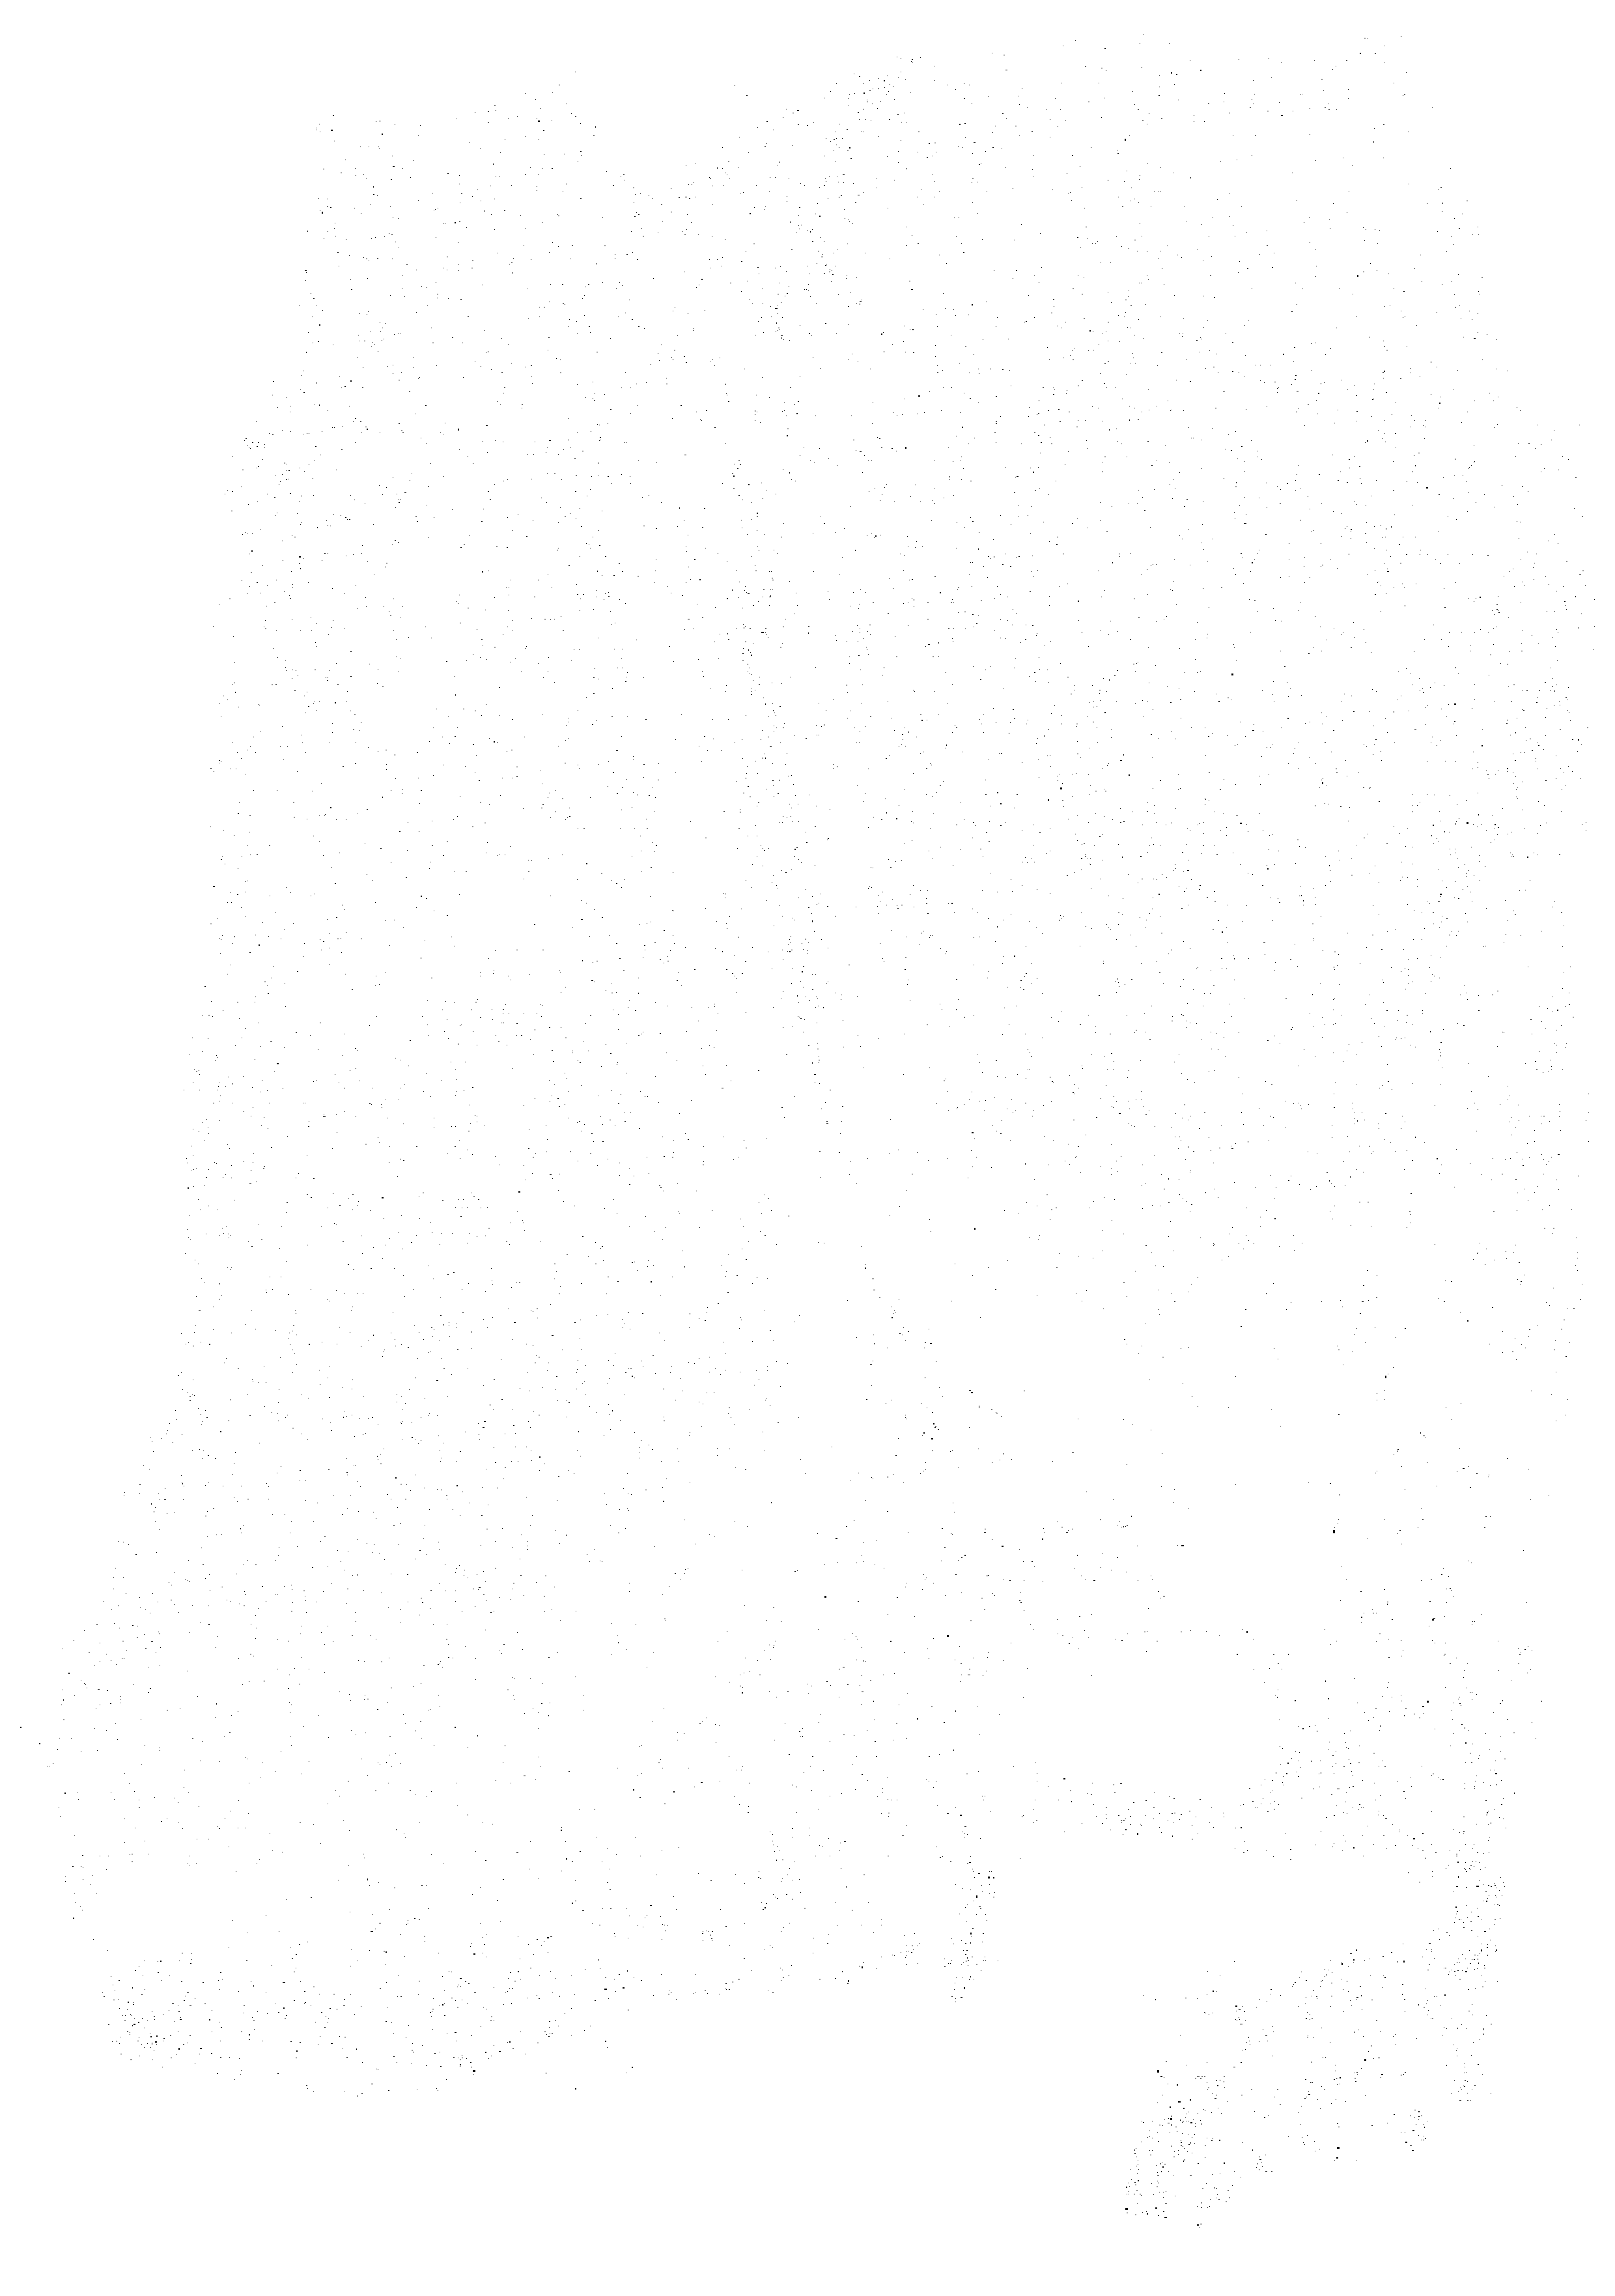

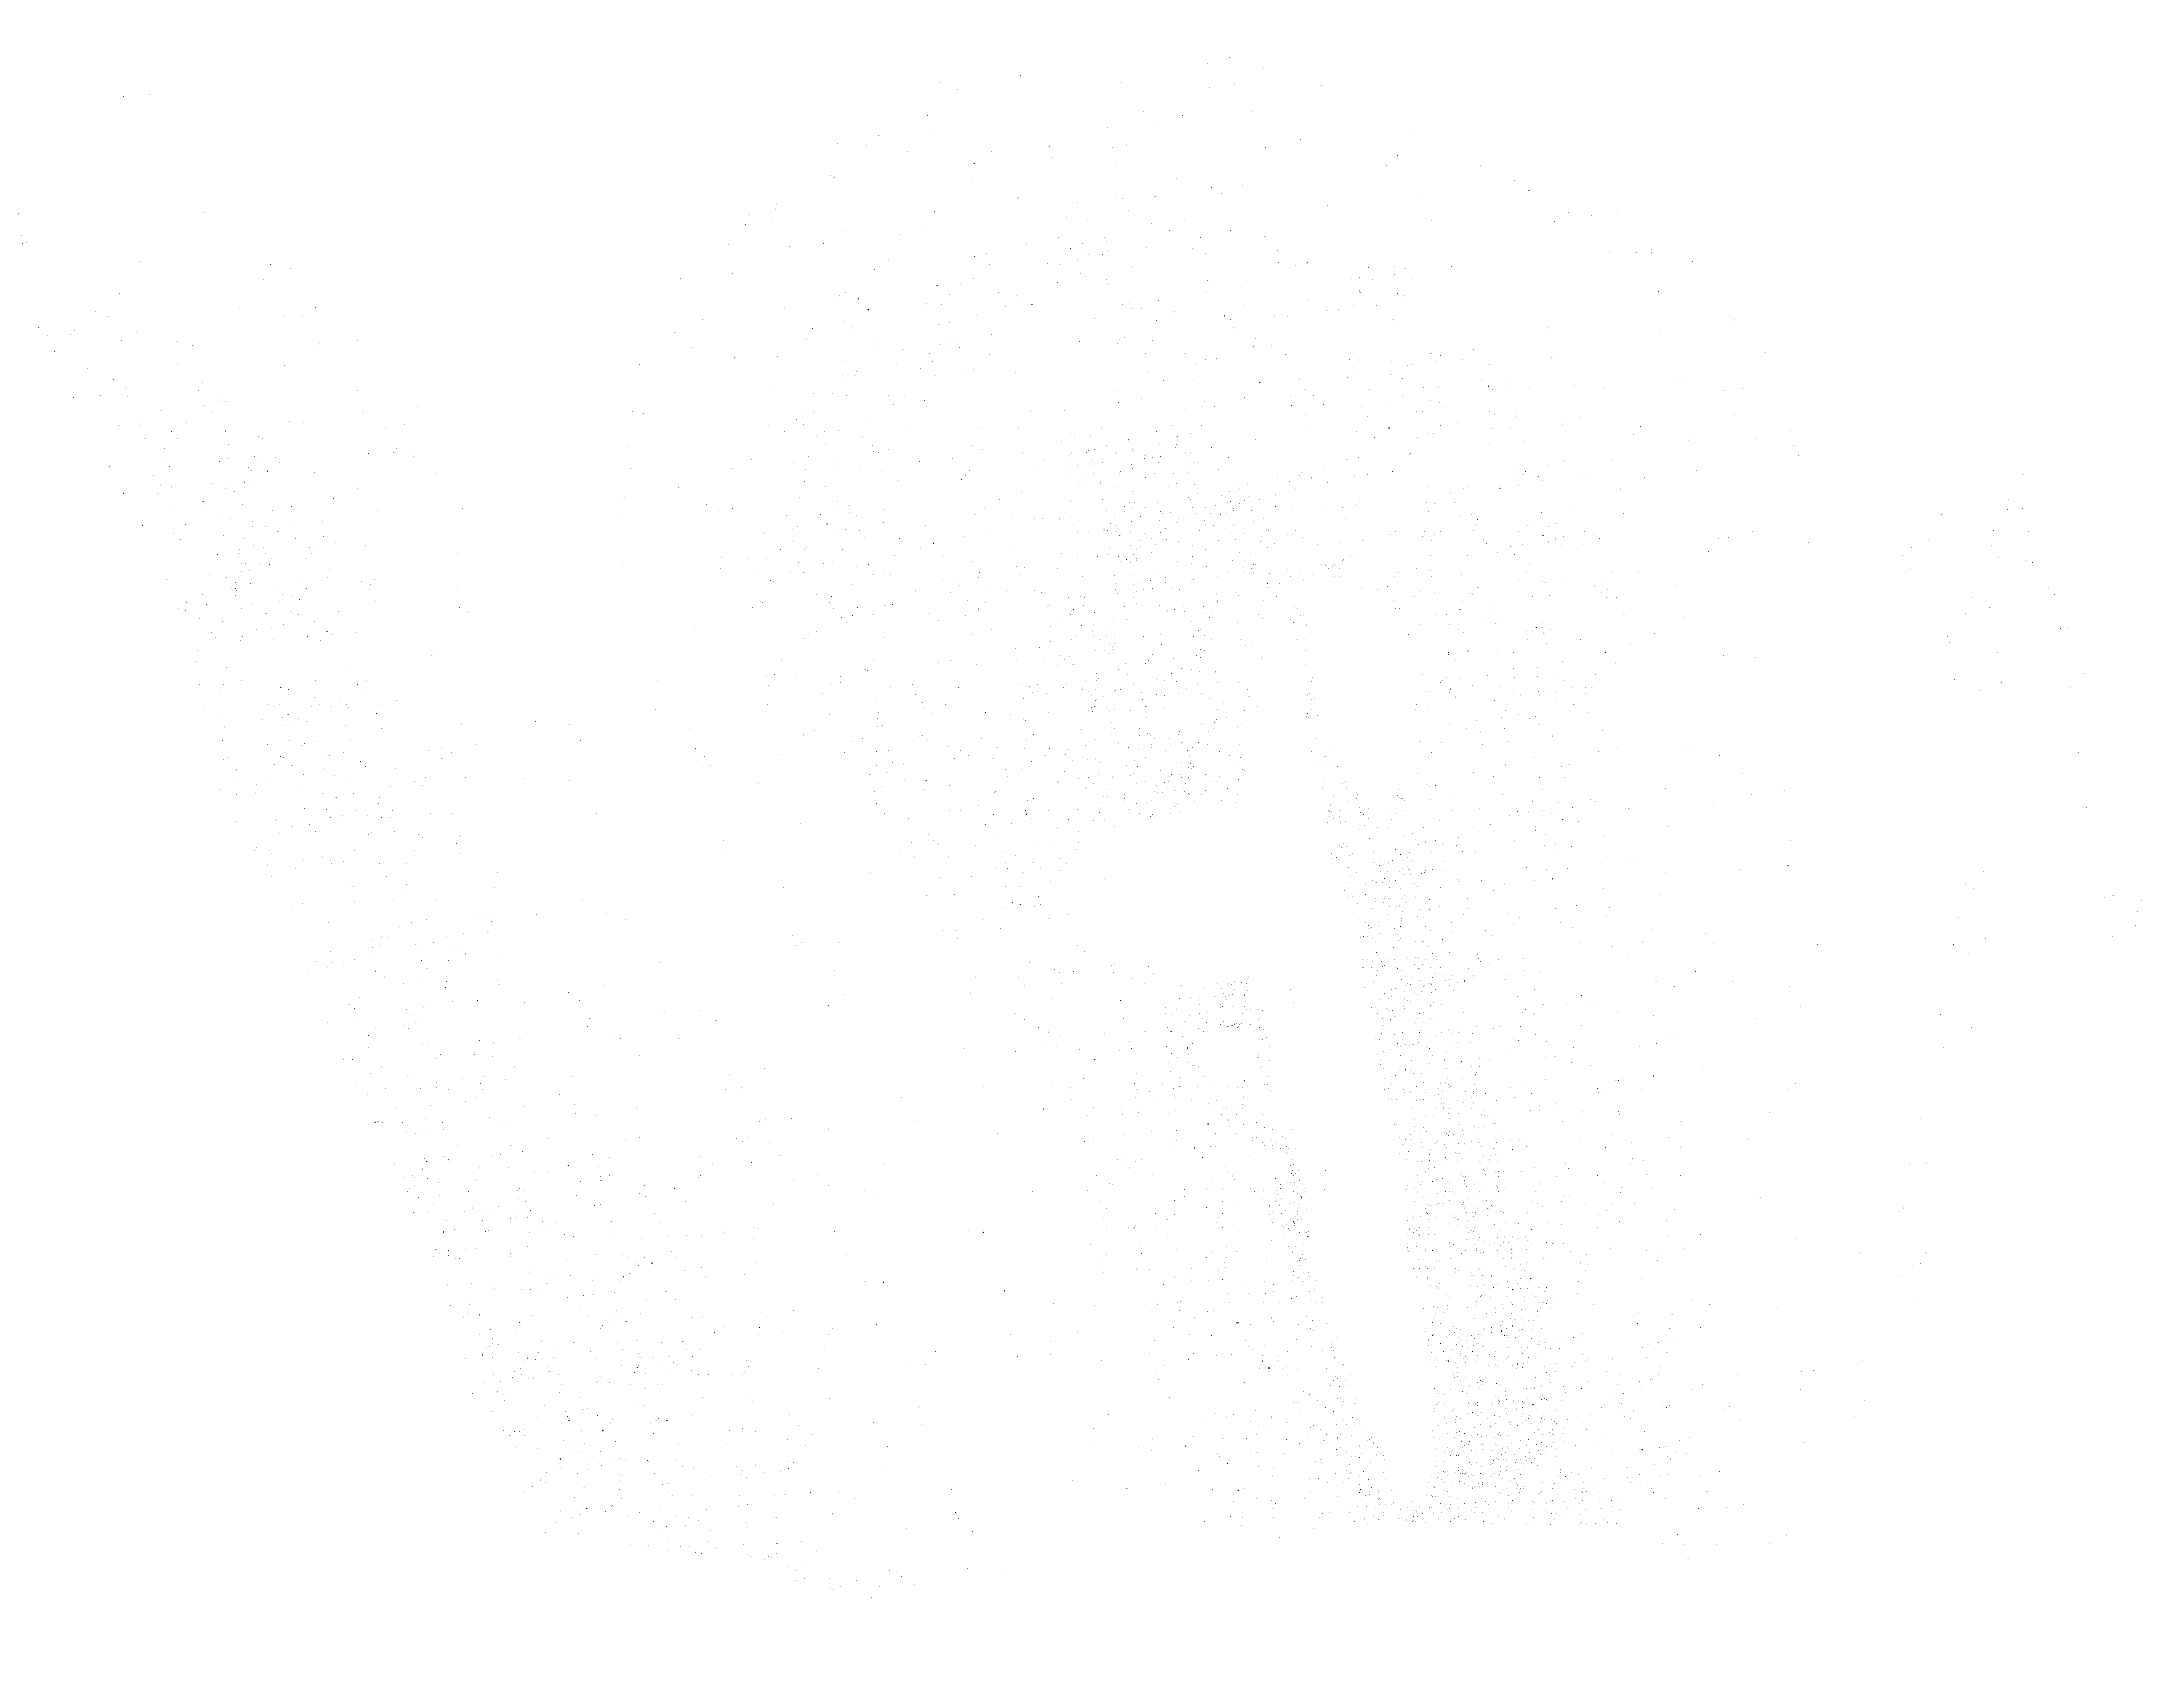

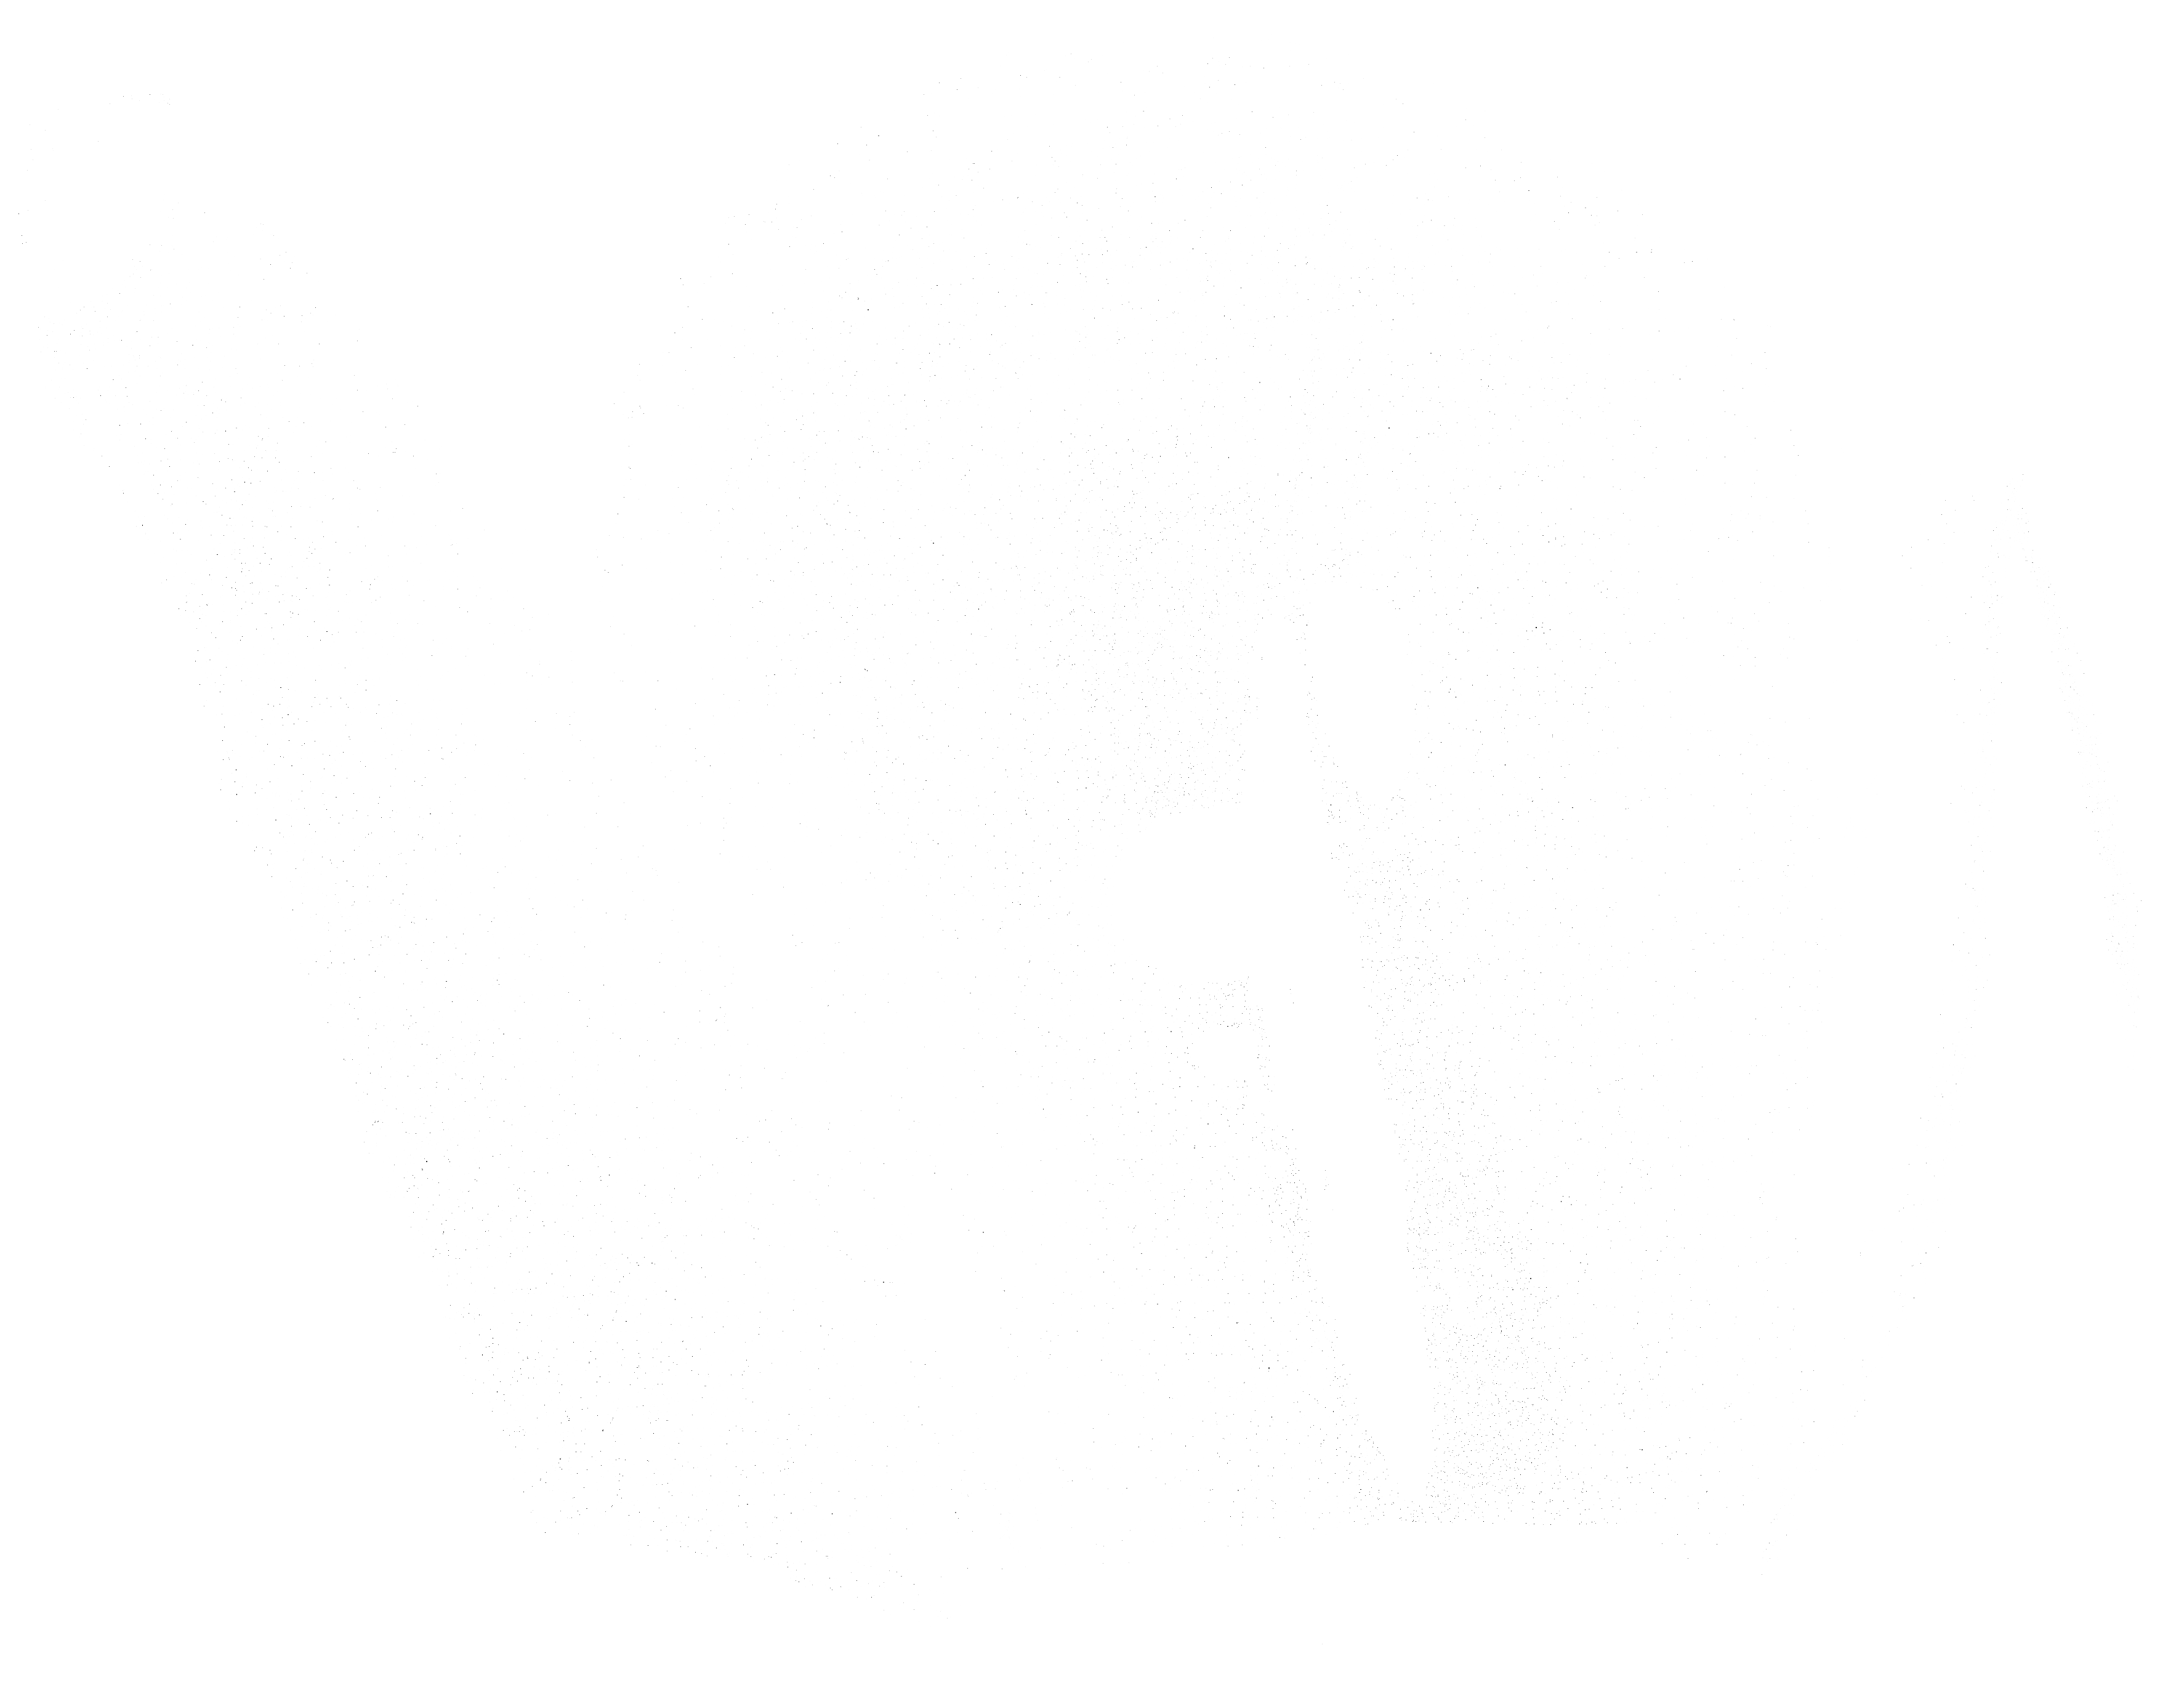

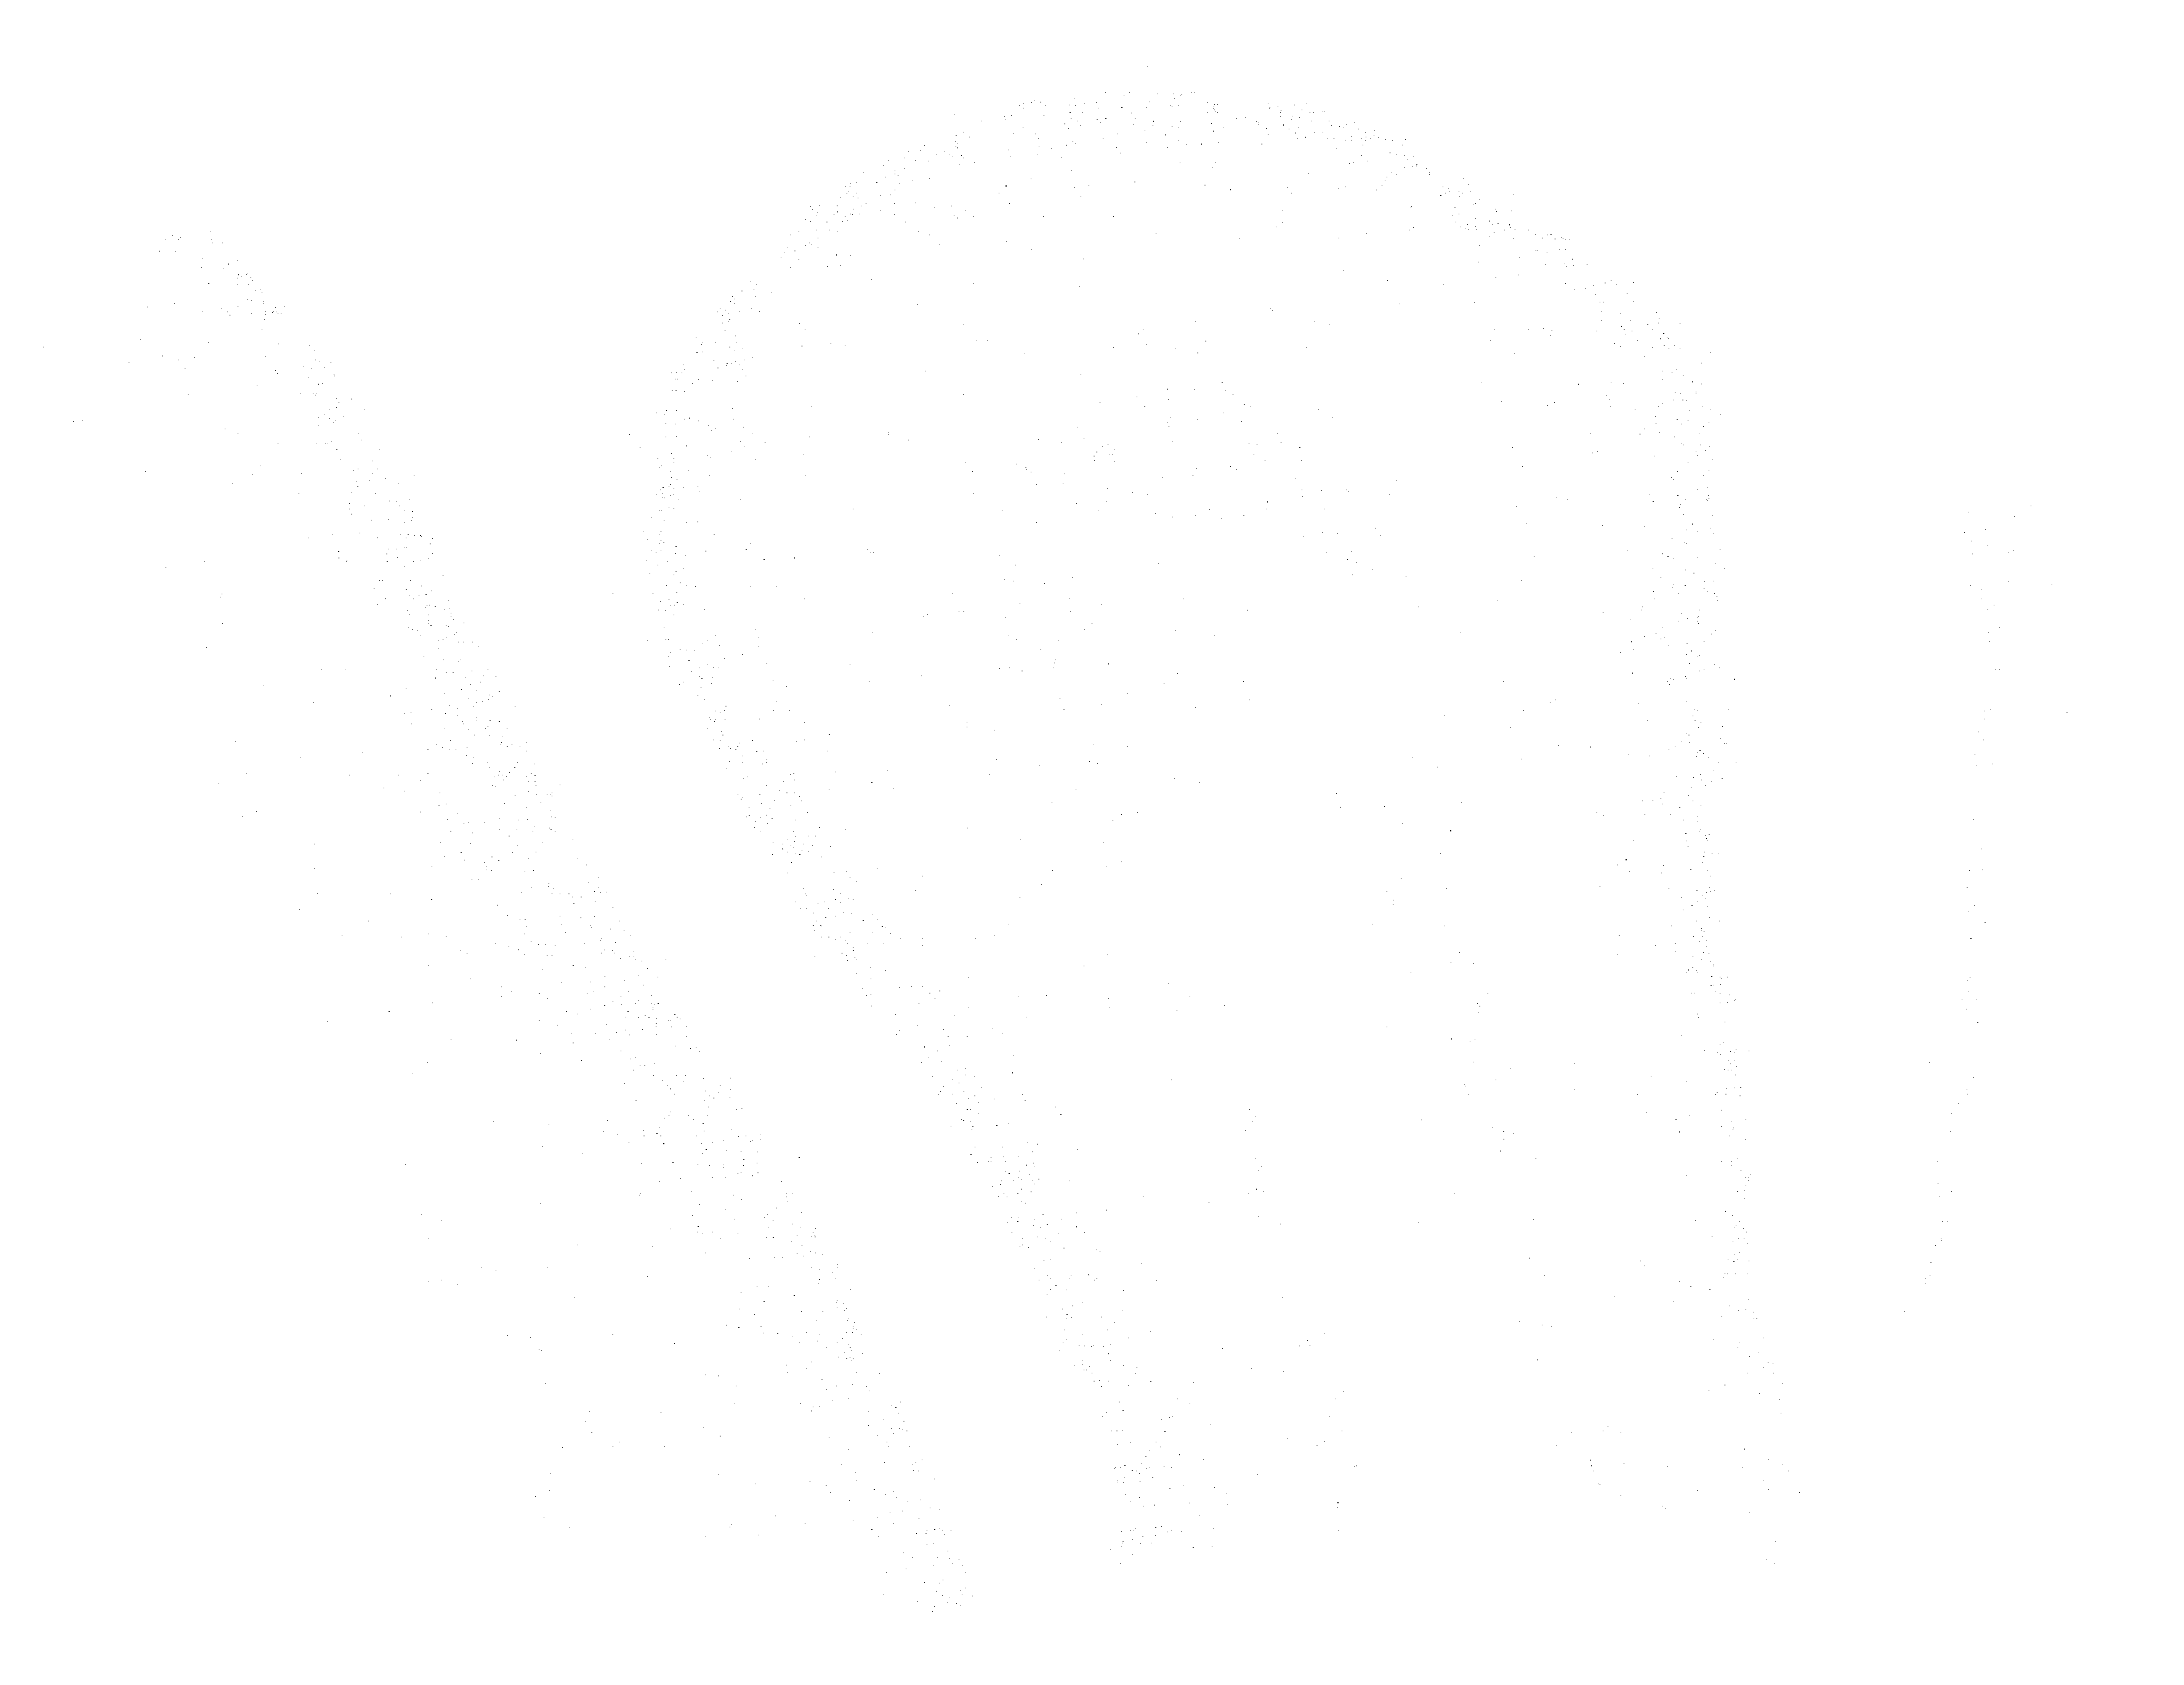

In [ ]:
# oligo counts, oligo intensity
metric_list = ['MBP_Oligo', 'MBP (Opal 520) Nucleus Intensity', 'HPCAL1_L2_neuron', 'DAPI (DAPI) Positive']

for n in range(0,len(paths)):
    for m in range(0,len(metric_list)):
        bin_size = 1
        df = pd.read_csv(paths[n])
        sample_id = paths[n].split('Br')[1].split('_DLPFC')[0]
        metric = metric_list[m]

        # Determine number of elements in X of matrix
        X = df['XMax'].max()-df['XMin'].min()

        # Determin number of elements in Y of matrix
        Y = df['YMax'].max()-df['YMin'].min()

        def make_matrix(column):
            image = np.zeros(shape=(X,Y))

            for element in range(0, len(df[column])):
                for x in range(df['XMin'][element]-df['XMin'].min(), df['XMax'][element]-df['XMax'].min()):
                    for y in range(df['YMin'][element]-df['YMin'].min(), df['YMax'][element]-df['YMax'].min()):
                        image[x, y] = df[column][element]*255
            return image

        image = make_matrix(metric)

        pd.DataFrame(bin_image(image, bin_size = bin_size)).to_csv('../../processed_data/08_validation_oligos/Br%s_array_%sx%sbinned_%s.txt' % (sample_id, bin_size, bin_size, metric))

        from matplotlib import pyplot as plt

        plt.figure(figsize=(15, 15), dpi=300)
        plt.imshow(bin_image(image, bin_size = bin_size), interpolation = 'nearest', cmap = 'Greys')
        plt.gca().set_axis_off()
        plt.savefig('../../plots/08_validation_oligos/Br%s_array_%sx%sbinned_%s.png' % (sample_id, bin_size, bin_size, metric), bbox_inches = 'tight', dpi = 300)
        plt.show()

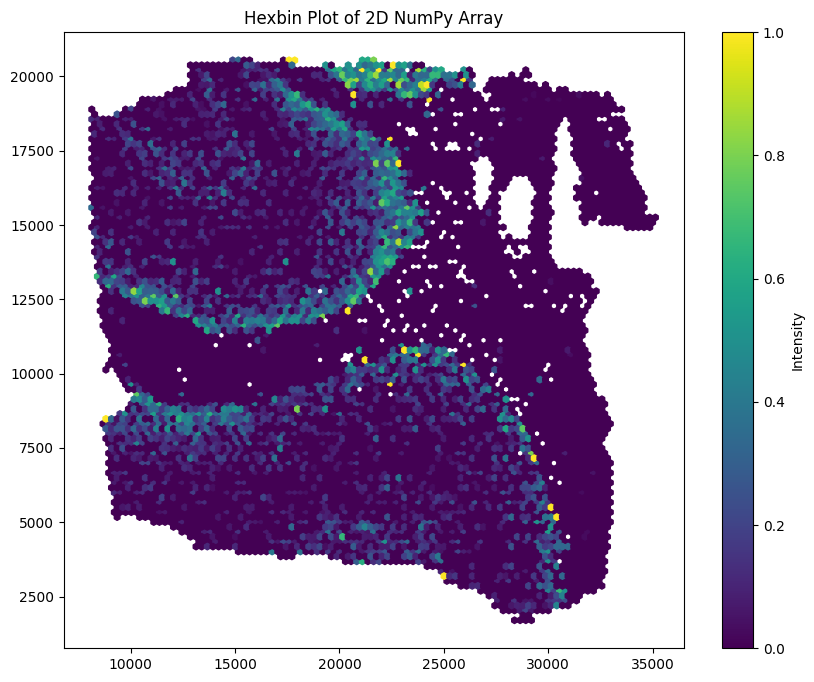

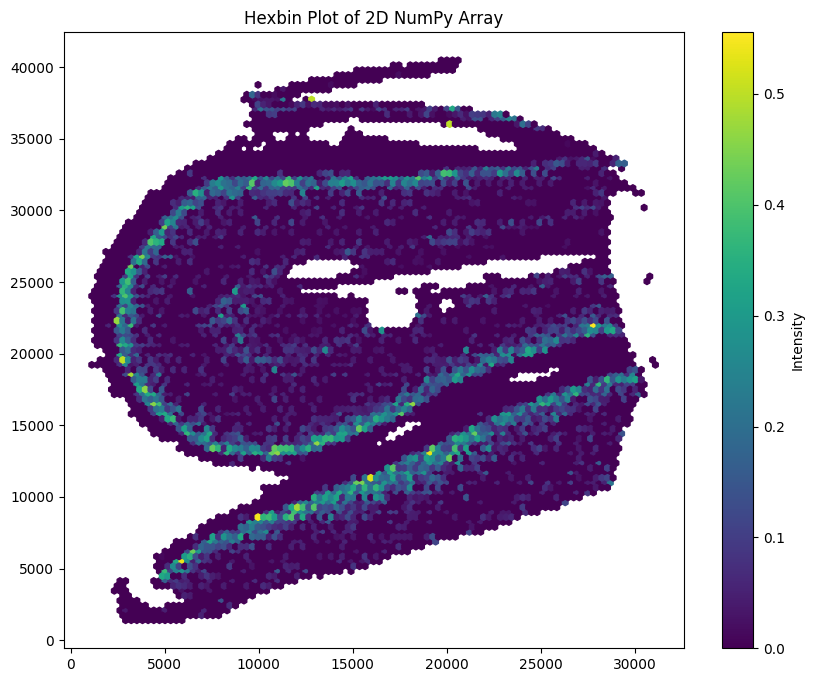

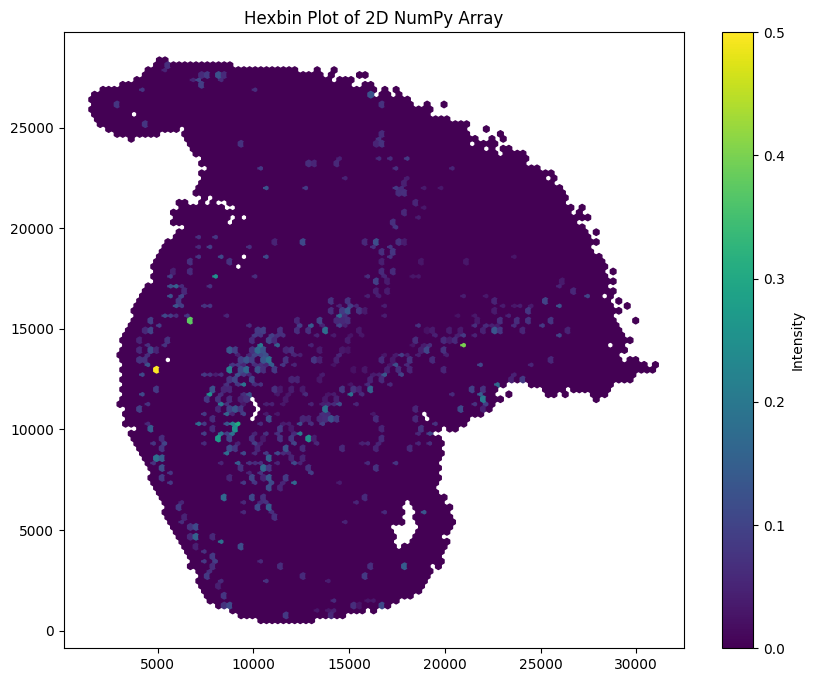

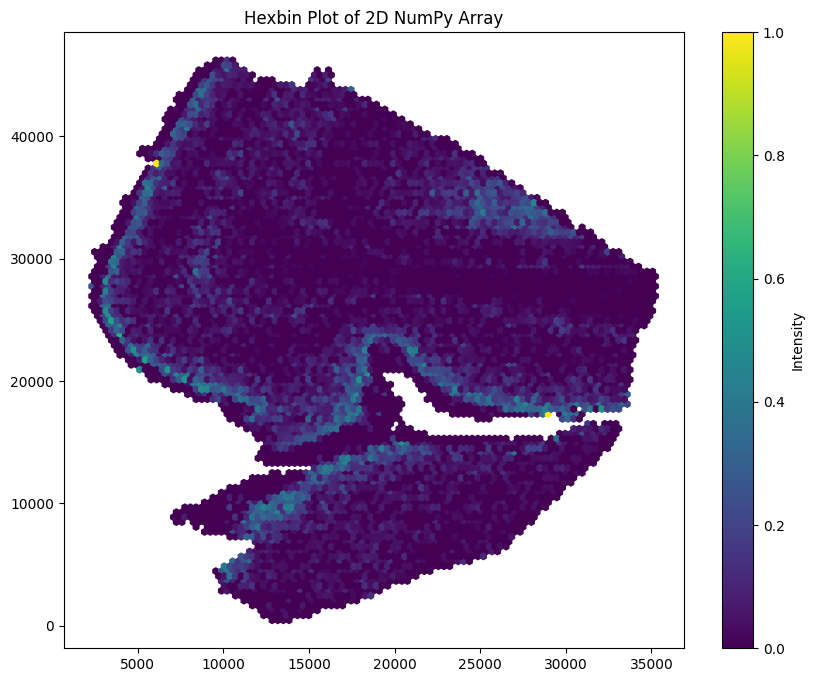

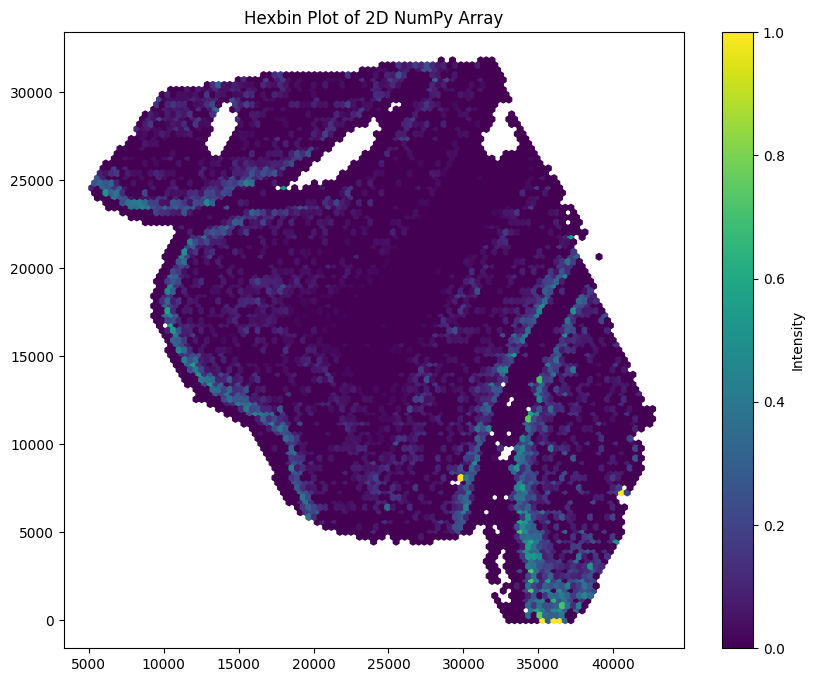

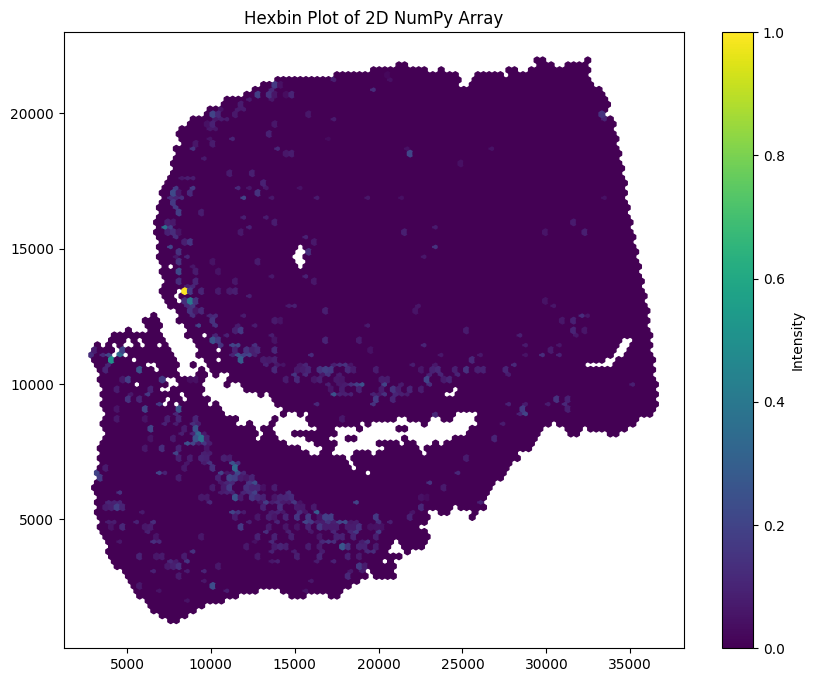

In [37]:
for n in range(0,len(paths)):
    bin_size = 128
    df = pd.read_csv(paths[n])
    sample_id = paths[n].split('Br')[1].split('_DLPFC')[0]
    plt.figure(figsize=(10, 8), dpi=100)
    plt.hexbin(df['XMin'], df['YMin'], C=df['HPCAL1 (Opal 570) Positive'], gridsize=100, cmap='viridis')
    plt.colorbar(label="Intensity")
    plt.title("Hexbin Plot of 2D NumPy Array")
    plt.show()

In [39]:
df

,Image Location,Analysis Region,Algorithm Name,Object Id,XMin,XMax,YMin,YMax,MBP_Oligo,HPCAL1_L2_neuron,...,HPCAL1 (Opal 570) Positive Cytoplasm,HPCAL1 (Opal 570) Cytoplasm Intensity,HPCAL1 (Opal 570) Positive Membrane,HPCAL1 (Opal 570) Membrane Intensity,Cell Area (µm²),Cytoplasm Area (µm²),Membrane Area (µm²),Nucleus Area (µm²),Nucleus Perimeter (µm),Nucleus Roundness
0,D:\RZ\Br9413_DLPFC_Fused.tif,Layer 1,Indica Labs - FISH-IF v2.1.5,0,6827,6852,1637,1659,0,0,...,0,0.002692,0,0,107.416060,80.901970,0,26.514091,23.368862,0.811753
1,D:\RZ\Br9413_DLPFC_Fused.tif,Layer 1,Indica Labs - FISH-IF v2.1.5,1,6849,6872,1654,1677,1,0,...,0,0.002204,0,0,103.955020,77.626335,0,26.328678,22.374443,0.932453
2,D:\RZ\Br9413_DLPFC_Fused.tif,Layer 1,Indica Labs - FISH-IF v2.1.5,2,7685,7708,1277,1299,1,0,...,0,0.000811,0,0,99.937730,75.463180,0,24.474546,21.380024,0.837401
3,D:\RZ\Br9413_DLPFC_Fused.tif,Layer 1,Indica Labs - FISH-IF v2.1.5,3,7589,7620,1301,1325,1,0,...,0,0.002444,0,0,148.577790,103.336970,0,45.240826,30.827011,0.729914
4,D:\RZ\Br9413_DLPFC_Fused.tif,Layer 1,Indica Labs - FISH-IF v2.1.5,4,7682,7705,1301,1322,0,0,...,0,0.000731,0,0,96.291270,75.648600,0,20.642672,20.385603,0.762691
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113605,D:\RZ\Br9413_DLPFC_Fused.tif,Layer 1,Indica Labs - FISH-IF v2.1.5,113605,30402,30431,21705,21726,0,0,...,0,0.000968,0,0,121.136640,90.234436,0,30.902205,25.854912,0.666908
113606,D:\RZ\Br9413_DLPFC_Fused.tif,Layer 1,Indica Labs - FISH-IF v2.1.5,113606,30331,30351,21711,21729,0,0,...,0,0.000618,0,0,69.838980,59.826668,0,10.012314,13.424665,0.814644
113607,D:\RZ\Br9413_DLPFC_Fused.tif,Layer 1,Indica Labs - FISH-IF v2.1.5,113607,30110,30135,21723,21750,0,0,...,0,0.001777,0,0,123.794230,93.386460,0,30.407768,28.838171,0.669940
113608,D:\RZ\Br9413_DLPFC_Fused.tif,Layer 1,Indica Labs - FISH-IF v2.1.5,113608,30246,30258,21732,21746,0,0,...,0,0.000380,0,0,37.453472,27.070332,0,10.383141,12.927456,0.774349


In [41]:
df[['MBP (Opal 520) Positive',
       'MBP (Opal 520) Positive Nucleus', 'MBP (Opal 520) Nucleus Intensity',
       'MBP (Opal 520) Positive Cytoplasm',
       'MBP (Opal 520) Cytoplasm Intensity',
       'MBP (Opal 520) Positive Membrane', 'MBP (Opal 520) Membrane Intensity']]

,MBP (Opal 520) Positive,MBP (Opal 520) Positive Nucleus,MBP (Opal 520) Nucleus Intensity,MBP (Opal 520) Positive Cytoplasm,MBP (Opal 520) Cytoplasm Intensity,MBP (Opal 520) Positive Membrane,MBP (Opal 520) Membrane Intensity
0,0,0,1.647953,0,0.612952,0,0
1,1,1,6.226122,0,1.104384,0,0
2,1,1,4.046806,0,0.977545,0,0
3,1,1,3.340407,0,1.332416,0,0
4,0,0,0.254796,0,0.223417,0,0
...,...,...,...,...,...,...,...
113605,0,0,2.685803,0,0.553390,0,0
113606,0,0,1.217428,0,0.853950,0,0
113607,0,0,1.236723,0,0.643490,0,0
113608,0,0,0.498023,0,0.620463,0,0


In [ ]:
# oligo counts - MBP_Oligo
# oligo intensity - MBP (Opal 520) Nucleus Intensity
# HPCAL1 counts - HPCAL1_L2_neuron
# All nuclei - DAPI (DAPI) Positive